# Modelo 3. ConvNeXt-Tiny con la imagen de la galaxia

**Inferencia de propiedades físicas de galaxias a partir de imágenes multibanda** · Instituto Tecnológico y de Estudios Superiores de Monterrey · Maestría en Inteligencia Artificial Aplicada · **Equipo 24** · Colaboración con el Instituto de Astronomía de la UNAM

| Integrante | Matrícula |
|---|---|
| José Florencio Maguey Peralta | A01796727 |
| Erick Alberto Bustos Cruz | A01378966 |
| Luz Copelia Minutti Pérez | A01796921 |

**Asesores:** Dr. Iván Reyes Amezcua (ITESM) · Dr. Héctor Hernández Toledo y Dr. José Antonio Vázquez Mata (IA-UNAM)

**Fase de CRISP-ML(Q):** 3, *Machine Learning Model Engineering* (Studer et al. 2021). **Avance 4:** modelos alternativos.

## 1. Planteamiento

Este cuaderno construye, ajusta y evalúa uno de los seis modelos individuales del avance: una red **ConvNeXt-Tiny** que estima la masa estelar (log M\*), la tasa de formación estelar (log SFR) y el índice D4000 a partir de la imagen de DESI en las bandas g, r y z.

### 1.1 Qué es ConvNeXt

ConvNeXt (Liu et al. 2022) es una red convolucional diseñada partiendo de ResNet50 y modernizándola paso a paso con las decisiones que hicieron exitosos a los transformadores de visión, pero sin usar atención. Cada cambio se conservó solo si mejoraba la exactitud en ImageNet:

| Componente | ResNet50 | ConvNeXt-Tiny | Qué cambia en la práctica |
|---|---|---|---|
| Entrada (*stem*) | Convolución 7 × 7 con paso 2 y *max pooling* | Parches de 4 × 4 sin traslape (paso 4) | La imagen se resume desde el inicio en bloques, como en un transformador |
| Bloque básico | Convoluciones 1 × 1 → 3 × 3 → 1 × 1 | Convolución 7 × 7 por canal → LayerNorm → 1 × 1 (×4 canales) → GELU → 1 × 1 | Cada bloque ve una región mayor de la galaxia y mezcla la información de los canales por separado |
| Normalización | BatchNorm (estadísticas del lote) | LayerNorm (cada imagen por separado) | No depende del tamaño del lote |
| Etapas | 3, 4, 6 y 3 bloques | 3, 3, 9 y 3 bloques, con 96, 192, 384 y 768 canales | Más capacidad en la escala intermedia |
| Parámetros | 25.6 M | 28.6 M | Costo de cómputo similar (4.5 GFLOPs a 224 px) |

Con el mismo costo, ConvNeXt-Tiny alcanza 82.1 % de exactitud en ImageNet, frente a 76.1 % de la ResNet50 original. Según el estudio de ablación de los autores, una parte importante de esa ganancia viene de la receta de entrenamiento (AdamW, *stochastic depth*, decaimiento de la tasa por capa), que también usamos aquí.

### 1.2 Qué puede aportar a nuestro problema

- **Estabilidad con lotes pequeños.** En el modelo 1 del equipo hubo que congelar las estadísticas de BatchNorm de ResNet50 porque los lotes de 16 a 32 imágenes son demasiado pequeños para estimarlas. LayerNorm elimina ese problema.
- **Estructura extendida.** Los filtros de 7 × 7 captan mejor el disco y los brazos de una galaxia, la estructura que en el Avance 3 resultó más informativa para estimar la SFR.
- **Experiencia previa en astronomía.** Zoobot, el modelo de morfología de Galaxy Zoo, ofrece versiones ConvNeXt, y hay clasificadores morfológicos recientes con codificadores ConvNeXt (Fang et al. 2025).

### 1.3 Preguntas que responde este cuaderno

1. Con el mismo protocolo, ¿una red convolucional moderna supera a ResNet50 (variantes F y G del modelo 1)?
2. ¿Ayuda dar al modelo un redshift estimado desde la propia imagen?
3. ¿Qué preentrenamiento se transfiere mejor a imágenes de galaxias: ImageNet-22k, ImageNet-1k o la versión de ConvNeXt destilada de DINOv3?

Solo cambia el extractor de la imagen: los datos, las cabezas, la pérdida y el criterio de selección son los del modelo 1, así que las diferencias se pueden atribuir a la arquitectura.


**Restricción de uso.** Los asesores indicaron que, en la práctica, de cada galaxia nueva solo se tendrá su imagen: el redshift no estará disponible al predecir. Por eso ningún modelo de este cuaderno recibe el redshift medido. Lo evaluamos de dos formas:

- **Solo con la imagen.**
- **En dos etapas:** primero estimamos el redshift a partir de la misma imagen (sección 5) y después lo damos al modelo junto con la imagen. Al predecir, el modelo sigue necesitando solo la imagen.

El redshift medido solo se usa como etiqueta para entrenar esa estimación y, en el diagnóstico, para revisar si el error depende de la distancia.

### Protocolo común de comparación

Los seis modelos del avance se comparan con las mismas reglas, de modo que las diferencias se puedan atribuir al algoritmo y no a cambios en los datos o en la forma de medir. Las reglas son las del modelo 1 del equipo (ResNet50 multitarea), y sus variantes F y G, que tampoco usan el redshift, son la referencia directa.

| Elemento | Regla común |
|---|---|
| Muestra | Galaxias con QCFLAG = 0, etiquetas y redshift válidos, y sin bandas vacías en el recorte; misma partición de entrenamiento, validación y prueba |
| Imagen | Bandas g, r y z en flujo físico, con `asinh(f / s_b)` (s_b: percentil 75 de \|f\| en entrenamiento) y estandarización por banda con entrenamiento |
| Entradas al predecir | Solo la imagen. En la variante en dos etapas, además, el redshift estimado desde la imagen, estandarizado con entrenamiento y unido al vector de la imagen antes de las cabezas |
| Salidas | Tres cabezas en paralelo, `Linear(d + k, 256) → ReLU → Dropout(0.1) → Linear(256, 1)`, con k = 0 o 1 variables escalares, sobre etiquetas estandarizadas |
| Aumentación | Giros de 90° y reflejos en entrenamiento; nada en validación y prueba |
| Criterio de selección | Promedio entre propiedades del MSE normalizado, (RMSE / σ_entrenamiento)²; se conserva la época con el menor valor en validación |
| Métricas | MAE, RMSE, sesgo y R² por propiedad, en su escala original, y el tiempo de entrenamiento |
| Semillas | 42, 7 y 2026; la semilla 42 representa al modelo en la tabla comparativa |
| Prueba | Se abre una sola vez, al final, con la elección registrada antes |

## 2. Parámetros

| Parámetro | Valor | Significado |
|---|---|---|
| `SEMILLAS` | 42, 7, 2026 | Semillas del entrenamiento; la 42 representa al modelo |
| `VARIANTES_ENTRADA` | solo imagen; imagen + redshift estimado | Las dos formas de usar el modelo que respetan la restricción |
| `EPOCAS` | 30 | Épocas de cada entrenamiento completo |
| `PRUEBAS_BUSQUEDA` | 30 | Configuraciones que prueba la búsqueda de hiperparámetros |
| `EPOCAS_BUSQUEDA` | 12 | Épocas máximas de cada prueba de la búsqueda (las poco prometedoras se detienen antes) |
| `FINALISTAS` | 3 | Mejores configuraciones de la búsqueda que se reentrenan con todas las épocas |
| `N_REMUESTREOS` | 2000 | Remuestreos *bootstrap* para los intervalos de confianza |
| `MARGEN` | 0.02, 0.02, 0.01 | Diferencia de RMSE que se considera despreciable en log M\*, log SFR y D4000 |

In [1]:
import os
variable_entorno = os.environ.get          # las variables MA_* solo se usan en la prueba local reducida

SEMILLAS = tuple(int(s) for s in variable_entorno("MA_SEMILLAS", "42,7,2026").split(","))
EPOCAS = int(variable_entorno("MA_EPOCAS", "30"))
PRUEBAS_BUSQUEDA = int(variable_entorno("MA_PRUEBAS", "30"))
EPOCAS_BUSQUEDA = int(variable_entorno("MA_EPOCAS_BUSQUEDA", "12"))
FINALISTAS = int(variable_entorno("MA_FINALISTAS", "3"))
N_REMUESTREOS = int(variable_entorno("MA_REMUESTREOS", "2000"))
LIMITE_GALAXIAS = int(variable_entorno("MA_LIMITE", "0"))           # 0 = todas las galaxias
PREENTRENADO = variable_entorno("MA_PREENTRENADO", "1") == "1"
LADO_ENTRADA = int(variable_entorno("MA_LADO", "300"))
EXTRACTOR_BASE = variable_entorno("MA_EXTRACTOR", "convnext_tiny.fb_in22k_ft_in1k")
PESOS_CANDIDATOS = tuple(variable_entorno("MA_PESOS_CANDIDATOS",
                                          "convnext_tiny.fb_in22k_ft_in1k,convnext_tiny.fb_in1k,convnext_tiny.dinov3_lvd1689m").split(","))

from pathlib import Path
BASE_DRIVE = Path(variable_entorno("MA_BASE", "/content/drive/MyDrive"))
CARPETA_RESULTADOS = "resultados_modelos_alternativos"
NOMBRE_MODELO = "modelo3_convnext_tiny_imagen"
OBJETIVOS = ("log_mstar", "log_sfr", "d4000")
VARIANTES_ENTRADA = {"solo imagen": (), "imagen + redshift estimado": ("redshift_predicho",)}
NOMBRES = {"log_mstar": "log M* [dex]", "log_sfr": "log SFR [dex]", "d4000": "D4000"}
CORTO = {"log_mstar": "M*", "log_sfr": "SFR", "d4000": "D4000"}
MARGEN = {"M*": 0.02, "SFR": 0.02, "D4000": 0.01}
CORTE_SSFR = -10.8                                                   # frontera entre galaxias formadoras y apagadas
ENTRADA_BASE = {"representacion": "grz_estandarizado", "lado": LADO_ENTRADA, "modo_lado": "recorte"}

## 3. Entorno

Descargamos el código del repositorio del equipo, de modo que cada resultado quede ligado a una versión concreta, e instalamos las bibliotecas que Colab no incluye: `timm` (modelos preentrenados) y `optuna` (búsqueda de hiperparámetros). Este cuaderno necesita una GPU; recomendamos una A100. Si la sesión se interrumpe, al volver a ejecutarlo se retoman los entrenamientos ya terminados.

In [2]:
import sys, json, time, subprocess, platform, warnings
from pathlib import Path
from dataclasses import replace

EN_COLAB = "google.colab" in sys.modules
URL_REPOSITORIO = "https://github.com/erteck/InferenciaPropiedadesFisicas.git"
CARPETA_REPOSITORIO = Path(variable_entorno("MA_CARPETA_REPOSITORIO", "/content/InferenciaPropiedadesFisicas"))
if EN_COLAB:
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "timm>=1.0.20", "optuna>=4", "hickle"], check=True)
    from google.colab import drive
    drive.mount("/content/drive")
    if not CARPETA_REPOSITORIO.exists():
        subprocess.run(["git", "clone", "-q", URL_REPOSITORIO, str(CARPETA_REPOSITORIO)], check=True)
    subprocess.run(["git", "-C", str(CARPETA_REPOSITORIO), "pull", "-q"], check=True)
sys.path.insert(0, str(CARPETA_REPOSITORIO))
COMMIT = subprocess.run(["git", "-C", str(CARPETA_REPOSITORIO), "rev-parse", "HEAD"], capture_output=True, text=True).stdout.strip()

warnings.filterwarnings("ignore")
import numpy as np, pandas as pd, torch, timm, optuna
import matplotlib.pyplot as plt
from IPython.display import display

from src.modelos_alternativos import arquitecturas, busqueda, evaluacion, experimento, interpretacion
from src.modelos_alternativos.arquitecturas import EspecificacionModelo
from src.modelos_alternativos.contexto import preparar_contexto
from src.modelos_alternativos.entrenamiento import ConfiguracionEntrenamiento
from src.katachi_fits.diagnostico import radio_mitad_luz

DISPOSITIVO = torch.device("cuda" if torch.cuda.is_available() else "cpu")
torch.backends.cudnn.benchmark = True
torch.backends.cuda.matmul.allow_tf32 = True
pd.set_option("display.precision", 4, "display.max_columns", 40, "display.width", 220)
plt.rcParams.update({"figure.dpi": 110, "font.size": 9, "axes.spines.top": False, "axes.spines.right": False})
print("Python", platform.python_version(), "· commit", COMMIT[:12], "· timm", timm.__version__, "· optuna", optuna.__version__,
      "·", DISPOSITIVO, torch.cuda.get_device_name(0) if DISPOSITIVO.type == "cuda" else "")

Mounted at /content/drive
Python 3.13.16 · commit 29785a315e24 · timm 1.0.30 · optuna 5.0.0 · cuda NVIDIA A100-SXM4-40GB


## 4. Datos

Preparamos la muestra y las transformaciones con las reglas del protocolo común. Todos los parámetros (la escala de compresión de cada banda y las medias y desviaciones de la imagen y de las etiquetas) se calculan solo con las galaxias de entrenamiento y se aplican sin cambios a validación y prueba. Los conteos de la muestra se calculan aquí, no se imponen.

In [3]:
CONTEXTO = preparar_contexto(BASE_DRIVE, CARPETA_RESULTADOS, OBJETIVOS, limite_galaxias=LIMITE_GALAXIAS)
CARPETA_MODELO = CONTEXTO.guardia.mkdir(BASE_DRIVE / CARPETA_RESULTADOS / NOMBRE_MODELO)
MUESTRA, INDICES = CONTEXTO.muestra, CONTEXTO.indices
TIPO_GALAXIA = np.where(MUESTRA.log_ssfr < CORTE_SSFR, "apagada", "formadora")
display(pd.crosstab(MUESTRA.particion, pd.Series(TIPO_GALAXIA, name="tipo de galaxia", index=MUESTRA.index), margins=True,
                    margins_name="total").loc[["Train", "Validation", "Test", "total"]])
if len(CONTEXTO.excluidas):
    display(CONTEXTO.excluidas.groupby(["particion", "motivo"]).size().rename("galaxias").reset_index())
t = CONTEXTO.transformacion_grz
display(pd.DataFrame({"s_b (percentil 75 de |f|)": t.escala_asinh, "media tras asinh": t.media, "desviación tras asinh": t.desviacion},
                     index=["g", "r", "z"]).round(5))
RADIO_MITAD_LUZ = radio_mitad_luz(CONTEXTO.imagenes, banda=1)          # en píxeles de la imagen de 300 px, banda r
print(f"Radio de mitad de luz (banda r): mediana {np.median(RADIO_MITAD_LUZ):.1f} px")

Muestra: 9299 galaxias (Train 7121, Validation 1261, Test 917) · excluidas: 4


tipo de galaxia,apagada,formadora,total
particion,,,
Train,3745,3376,7121
Validation,676,585,1261
Test,465,452,917
total,4886,4413,9299


,particion,motivo,galaxias
0,Test,banda completa en cero,1
1,Train,banda completa en cero,1
2,Train,redshift no válido,1
3,Validation,banda completa en cero,1


,s_b (percentil 75 de |f|),media tras asinh,desviación tras asinh
g,0.0039,0.4967,1.0310
r,0.0074,0.5076,1.0334
z,0.0161,0.3651,0.9897


Radio de mitad de luz (banda r): mediana 22.1 px


La figura muestra lo que recibe la red: los tres canales estandarizados (z, r y g como rojo, verde y azul) en el recorte central de 300 × 300 píxeles, que es la entrada de ConvNeXt. Las galaxias van de menor a mayor masa, y en ellas se ve lo que el modelo tiene que aprender a leer: el color se vuelve más rojo y la luz más concentrada al aumentar la masa y bajar la formación de estrellas. El círculo marca el radio que encierra la mitad de la luz (R50), la escala con la que después medimos qué regiones de la galaxia usa el modelo.

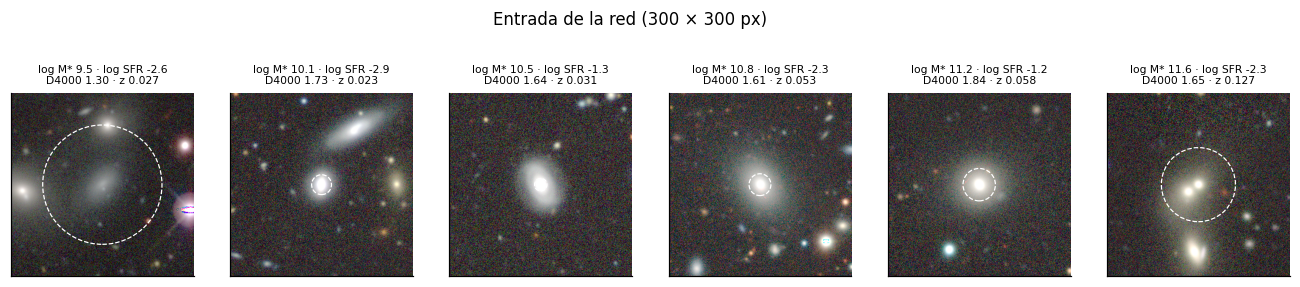

In [4]:
PREPARADOR_VISTA = experimento.crear_preparador(CONTEXTO, ENTRADA_BASE)
entrenamiento = MUESTRA.iloc[INDICES["Train"]]
ejemplos = [entrenamiento.index[np.argmin(np.abs(entrenamiento.log_mstar.to_numpy() - q))]
            for q in np.quantile(entrenamiento.log_mstar, np.linspace(0.05, 0.95, 6))]
fig, ejes = plt.subplots(1, 6, figsize=(15, 2.9))
for eje, i in zip(ejes, ejemplos):
    x = PREPARADOR_VISTA(torch.from_numpy(CONTEXTO.imagenes[i:i + 1].astype(np.float32)))[0].numpy()[[2, 1, 0]]
    if PREPARADOR_VISTA.representacion == "rgb_lupton":
        x = x[[2, 1, 0]]
    rgb = np.transpose(x, (1, 2, 0)); rgb = np.clip((rgb - np.percentile(rgb, 1)) / (np.percentile(rgb, 99.7) - np.percentile(rgb, 1)), 0, 1)
    eje.imshow(rgb, origin="lower")
    escala = x.shape[-1] / 300 if PREPARADOR_VISTA.modo_lado == "reescala" else 1
    eje.add_patch(plt.Circle(((x.shape[-1] - 1) / 2,) * 2, RADIO_MITAD_LUZ[i] * escala, fill=False, color="w", lw=0.8, ls="--"))
    g = MUESTRA.loc[i]
    eje.set_title(f"log M* {g.log_mstar:.1f} · log SFR {g.log_sfr:.1f}\nD4000 {g.d4000:.2f} · z {g.redshift:.3f}", fontsize=7)
    eje.set_xticks([]); eje.set_yticks([])
plt.suptitle(f"Entrada de la red ({x.shape[-1]} × {x.shape[-1]} px)", y=1.04); plt.show()

## 5. Redshift estimado desde la imagen

La variante en dos etapas necesita un redshift que se pueda obtener de la imagen. Lo estimamos con un modelo sencillo: un extractor congelado de DINOv3 (ViT-B/16, preentrenado con imágenes web) que convierte cada imagen en un vector, y encima las mismas cabezas de regresión del protocolo, entrenadas para predecir log₁₀ z. Usamos el logaritmo porque los errores de distancia son relativos: equivocarse por 0.01 importa mucho más a z = 0.02 que a z = 0.12.

Para que la segunda etapa aprenda con estimaciones del mismo nivel de error que tendrá con galaxias nuevas, las construimos con cuidado:

- **Galaxias de entrenamiento: predicciones fuera de partición** (*cross-fitting*; Wolpert 1992). Dividimos las galaxias de entrenamiento en 5 partes y estimamos cada parte con un modelo entrenado con las otras 4. Así ninguna galaxia recibe una estimación de un modelo que la vio. Si no lo hiciéramos, las estimaciones de entrenamiento serían casi perfectas, la segunda etapa aprendería a confiar en ellas y fallaría con galaxias nuevas.
- **Galaxias de validación y de prueba:** las estima un modelo entrenado con todas las galaxias de entrenamiento.
- **Época de cada modelo:** se elige con un 10 % de sus propias galaxias de ajuste, nunca con las galaxias que se van a estimar ni con validación.
- **Sin información de validación ni de prueba:** el redshift medido de esas galaxias no interviene en ningún ajuste. Calcular su estimación solo requiere sus imágenes, así que no equivale a abrir el conjunto de prueba; su calidad en prueba se reporta en la sección de evaluación final.

Todos los modelos alternativos reciben exactamente la misma estimación, de modo que sus diferencias no se deben a ella.

model.safetensors: reconstructing file:   0%|          |  0.00B /  343MB            

model.safetensors: downloading bytes:           |  0.00B            

,origen,n,sesgo_dz,sigma_NMAD_dz,atipicos_dz_mayor_0.05,error_relativo_mediano,RMSE_log10z,spearman
partición,,,,,,,,
Train,fuera de partición (5 partes),7121,-0.0002,0.0108,0.0129,0.1993,0.1387,0.7577
Validation,modelo con todo entrenamiento,1261,0.0010,0.0102,0.0063,0.1994,0.1334,0.7754


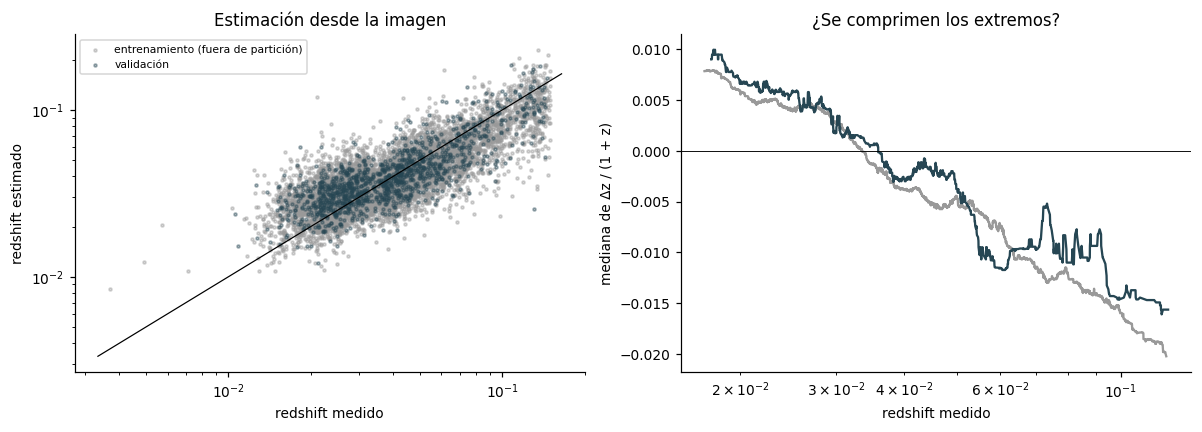

In [5]:
from src.modelos_alternativos.representaciones import ConfiguracionCabeza
from src.modelos_alternativos.variable_predicha import metricas_redshift, predecir_variable_desde_imagen

EXTRACTOR_ETAPA1 = variable_entorno("MA_EXTRACTOR_ETAPA1", "vit_base_patch16_dinov3.lvd1689m")
LADO_ETAPA1 = int(variable_entorno("MA_LADO_ETAPA1", "288"))
ESPEC_ETAPA1 = EspecificacionModelo(nombre_extractor=EXTRACTOR_ETAPA1, preentrenado=PREENTRENADO, lado_entrada=LADO_ETAPA1,
                                    estrategia_ajuste="congelado", agregacion_tokens="cls_y_promedio")
ENTRADA_ETAPA1 = {"representacion": "grz_estandarizado", "lado": LADO_ETAPA1, "modo_lado": "recorte"}
CABEZA_ETAPA1 = ConfiguracionCabeza(unidades_ocultas=256, dropout=0.1, tasa_aprendizaje=1e-3, decaimiento_pesos=1e-2,
                                    epocas=int(variable_entorno("MA_EPOCAS_ETAPA1", "300")), tamano_lote=256, perdida="huber",
                                    semilla=SEMILLAS[0])
TABLA_REDSHIFT = predecir_variable_desde_imagen(CONTEXTO, BASE_DRIVE / CARPETA_RESULTADOS / "etapa1_redshift_desde_imagen", "redshift",
                                                "redshift_predicho", ESPEC_ETAPA1, ENTRADA_ETAPA1, CABEZA_ETAPA1, DISPOSITIVO,
                                                n_particiones=5, fraccion_interna=0.1, transformacion="log10", semilla=SEMILLAS[0],
                                                registro=lambda *_: None)
filas = []
for particion, origen in (("Train", "fuera de partición (5 partes)"), ("Validation", "modelo con todo entrenamiento")):
    idx = INDICES[particion]
    filas.append({"partición": particion, "origen": origen,
                  **metricas_redshift(MUESTRA.redshift.to_numpy()[idx], MUESTRA.redshift_predicho.to_numpy()[idx])})
CALIDAD_REDSHIFT = pd.DataFrame(filas).set_index("partición")
display(CALIDAD_REDSHIFT.round(4))

fig, ejes = plt.subplots(1, 2, figsize=(11, 4))
for particion, color in (("Train", "0.6"), ("Validation", "#264653")):
    idx = INDICES[particion]
    z, zp = MUESTRA.redshift.to_numpy()[idx], MUESTRA.redshift_predicho.to_numpy()[idx]
    ejes[0].scatter(z, zp, s=4, alpha=0.4, color=color, label="entrenamiento (fuera de partición)" if particion == "Train" else "validación")
    dz = (zp - z) / (1 + z)
    orden = np.argsort(z); ventana = max(20, len(z) // 15)
    mediana = pd.Series(dz[orden]).rolling(ventana, center=True).median()
    ejes[1].plot(z[orden], mediana, color=color)
limites = [MUESTRA.redshift.min() * 0.9, MUESTRA.redshift.max() * 1.1]
ejes[0].plot(limites, limites, "k-", lw=0.8); ejes[0].set(xscale="log", yscale="log", xlabel="redshift medido", ylabel="redshift estimado",
                                                          title="Estimación desde la imagen"); ejes[0].legend(fontsize=7)
ejes[1].axhline(0, color="k", lw=0.6); ejes[1].set(xscale="log", xlabel="redshift medido", ylabel="mediana de Δz / (1 + z)",
                                                   title="¿Se comprimen los extremos?")
plt.tight_layout(); plt.show()

La estimación del redshift tiene una dispersión σ_NMAD de 0.010 en Δz/(1 + z), un sesgo prácticamente nulo y menos de 1.3 % de valores atípicos (|Δz|/(1 + z) > 0.05). Estas cifras parecen pequeñas, pero hay que leerlas frente al intervalo de la muestra: las galaxias de MaNGA están entre z ≈ 0.01 y 0.15, así que el error relativo mediano es de 20 % y el error típico en log₁₀ z es de 0.13. La correlación de rangos con el redshift medido es de 0.76; el modelo ordena bien las galaxias de cercanas a lejanas, pero no fija su distancia con precisión.

Las métricas de entrenamiento, calculadas fuera de partición, y las de validación son casi iguales. Eso es lo que buscábamos con la validación cruzada: las estimaciones de entrenamiento tienen el mismo nivel de error que las que el modelo recibirá al predecir, de modo que la segunda etapa no aprende a confiar en ellas más de lo que merecen.

La gráfica de la derecha muestra el defecto principal de la estimación. La mediana de Δz/(1 + z) baja de +0.008 en z ≈ 0.02 a −0.015 en z ≈ 0.1: el modelo acerca los extremos al centro de la distribución, de modo que sobreestima la distancia de las galaxias cercanas y subestima la de las lejanas. Es el comportamiento esperado de una regresión con información limitada, y conviene tenerlo presente porque la masa y la SFR dependen de la distancia.

In [6]:
# Utilidades para resumir corridas con las métricas del protocolo común.
def registro_compacto(mensaje):
    # Durante el entrenamiento solo se muestra el avance cada 5 épocas.
    if mensaje.startswith("época") and int(mensaje.split()[1]) % 5 == 0:
        print(mensaje)

def registro_busqueda(mensaje):
    # De la búsqueda solo se muestran las pruebas que fallan.
    if "falló" in mensaje:
        print(mensaje)

def grafica_hiperparametros(pruebas, importancia, referencia=None, n=3, titulo="", siempre=(), etiqueta_referencia="configuración de partida"):
    # Criterio de validación frente a los n hiperparámetros más importantes de la búsqueda (más los de `siempre`).
    terminadas = pruebas[pruebas.estado == "complete"]
    nombres = [h for h in siempre if h in terminadas]
    nombres += [h for h in (importancia.index if len(importancia) else []) if h in terminadas and h not in nombres][:max(0, n - len(nombres))]
    if not nombres:
        return
    fig, ejes = plt.subplots(1, len(nombres) + 1, figsize=(4.2 * (len(nombres) + 1), 3.4))
    orden = terminadas.sort_values("prueba")
    ejes[0].scatter(orden.prueba, orden.criterio_validacion, s=16, color="#264653")
    ejes[0].plot(orden.prueba, orden.criterio_validacion.cummin(), color="C3", lw=1, label="mejor hasta el momento")
    if referencia is not None:
        ejes[0].axhline(referencia, color="k", ls=":", lw=1, label=etiqueta_referencia)
    ejes[0].set(xlabel="prueba", ylabel="criterio de validación", title="Avance de la búsqueda"); ejes[0].legend(fontsize=7)
    for eje, h in zip(ejes[1:], nombres):
        valores = terminadas[h]
        if pd.api.types.is_numeric_dtype(valores):
            eje.scatter(valores, terminadas.criterio_validacion, s=16, color="#264653")
            if (valores > 0).all() and valores.max() / valores.min() > 3:
                eje.set_xscale("log")
        else:
            categorias = sorted(valores.astype(str).unique())
            posicion = valores.astype(str).map({k: n for n, k in enumerate(categorias)})
            eje.scatter(posicion + np.random.default_rng(0).uniform(-0.12, 0.12, len(posicion)), terminadas.criterio_validacion,
                        s=16, color="#264653", alpha=0.7)
            medianas = terminadas.groupby(valores.astype(str)).criterio_validacion.median()
            eje.scatter(range(len(categorias)), [medianas[k] for k in categorias], marker="_", s=600, color="C3", label="mediana")
            eje.set_xticks(range(len(categorias)), [k.split(".")[-1] for k in categorias], rotation=15)
            eje.set_xlim(-0.6, len(categorias) - 0.4)
        importancia_h = f" · importancia {importancia[h]:.2f}" if h in importancia else ""
        eje.set(xlabel=h.replace("_", " "), title=f"{h.replace('_', ' ')}{importancia_h}")
    ejes[0].xaxis.get_major_locator().set_params(integer=True)
    ejes[1].set_ylabel("criterio de validación")
    plt.suptitle(titulo, y=1.03); plt.tight_layout(); plt.show()
def metricas_corrida(corrida, particion="Validation", tta=False):
    prediccion = experimento.predicciones_originales(CONTEXTO, corrida, particion, DISPOSITIVO, tta=tta)
    return experimento.tabla_corrida(CONTEXTO, prediccion, particion, corrida=corrida.identificador), prediccion

def resumen_corridas(corridas, etiqueta, particion="Validation"):
    # Media y desviación entre semillas de cada métrica; fila ancha por modelo.
    tablas = pd.concat([metricas_corrida(r, particion)[0].assign(semilla=r.resumen["configuracion"]["semilla"]) for r in corridas])
    variables = corridas[0].variables_escalares
    fila = {"modelo": etiqueta, "entradas": "solo imagen" if not variables else "imagen + " + ", ".join(variables).replace("_", " "),
            "solo_imagen_al_predecir": "sí", "semillas": len(corridas),
            "MSE_normalizado_medio": tablas.groupby("semilla").MSE_normalizado.mean().mean(),
            "desviacion_entre_semillas": tablas.groupby("semilla").MSE_normalizado.mean().std(ddof=1) if len(corridas) > 1 else np.nan}
    for objetivo, g in tablas.groupby("objetivo", sort=False):
        for m in ("RMSE", "MAE", "sesgo", "R2"):
            fila[f"{m} {CORTO[objetivo]}"] = g[m].mean()
    fila["minutos_entrenamiento"] = np.mean([r.resumen["minutos_entrenamiento"] for r in corridas])
    fila["parametros_entrenables_M"] = corridas[0].resumen["parametros_entrenables"] / 1e6
    return fila, tablas

## 6. Modelo base

El modelo base usa los pesos de ConvNeXt-Tiny preentrenados con ImageNet-22k y ajustados después con ImageNet-1k, que son los que mejor se transfieren según sus autores. Las tres bandas g, r y z entran en el lugar de los canales R, G y B, sin modificar la primera capa. El vector de 768 componentes que produce el extractor pasa a las tres cabezas del protocolo común; en la variante en dos etapas, antes se le une el redshift estimado.

La receta de entrenamiento sigue la de los autores de ConvNeXt para ajuste fino:

| Elemento | Valor | Motivo |
|---|---|---|
| Optimizador | AdamW, *weight decay* 0.05 | Regularización desacoplada de la tasa, estándar en ConvNeXt |
| Tasa del extractor | 1 × 10⁻⁴, con decaimiento por capa de 0.8 | Las capas iniciales, más genéricas, cambian menos que las finales |
| Tasa de las cabezas | 1 × 10⁻³ | Las capas nuevas aprenden más rápido que el extractor preentrenado |
| Programa | 2 épocas de calentamiento y descenso en coseno | Evita cambios bruscos al inicio, cuando las cabezas todavía son aleatorias |
| *Stochastic depth* | 0.1 | Regularización que omite bloques al azar durante el entrenamiento |
| Pérdida | Huber con δ = 1 sobre etiquetas estandarizadas | La misma del modelo 1 |
| Lote y precisión | 32 imágenes, bfloat16 | Aprovecha la A100 sin afectar la precisión de las predicciones |

Entrenamos esta configuración con las dos variantes de entrada y las tres semillas. La comparación entre las dos variantes, sobre las mismas galaxias y con las mismas semillas, mide directamente si el redshift estimado ayuda.

In [7]:
ESPECIFICACION_BASE = EspecificacionModelo(nombre_extractor=EXTRACTOR_BASE, preentrenado=PREENTRENADO, tasa_drop_path=0.1)
CONFIGURACION_BASE = ConfiguracionEntrenamiento(epocas=EPOCAS, epocas_calentamiento=2, tamano_lote=32, tasa_extractor=1e-4,
                                                tasa_cabeza=1e-3, decaimiento_pesos=0.05, decaimiento_por_capa=0.8, perdida="huber")
CORRIDAS_BASE, FILAS_BASE, TABLAS_BASE = {}, {}, []
for variante, variables in VARIANTES_ENTRADA.items():
    CORRIDAS_BASE[variante] = [experimento.ejecutar_corrida(CONTEXTO, CARPETA_MODELO, "base", ESPECIFICACION_BASE,
                                                            replace(CONFIGURACION_BASE, semilla=s), ENTRADA_BASE, DISPOSITIVO, variables,
                                                            registro=registro_compacto)
                               for s in SEMILLAS]
    FILAS_BASE[variante], tabla = resumen_corridas(CORRIDAS_BASE[variante], f"3 · ConvNeXt-Tiny base, {variante}")
    TABLAS_BASE.append(tabla.assign(variante=variante))
TABLAS_BASE = pd.concat(TABLAS_BASE)
display(TABLAS_BASE.pivot_table(index=["variante", "objetivo"], columns="semilla", values="RMSE").round(4))
for variante, fila in FILAS_BASE.items():
    print(f"{variante}: MSE normalizado medio {fila['MSE_normalizado_medio']:.4f} ± {fila['desviacion_entre_semillas']:.4f}"
          f" · {fila['minutos_entrenamiento']:.1f} min por entrenamiento")

# ¿Ayuda el redshift estimado? Diferencia pareada sobre las mismas galaxias y semillas (negativo = ayuda)
y_validacion = CONTEXTO.etiquetas("Validation")
filas = []
for solo, dos_etapas in zip(*CORRIDAS_BASE.values()):
    ps = experimento.predicciones_originales(CONTEXTO, solo, "Validation", DISPOSITIVO)
    pd2 = experimento.predicciones_originales(CONTEXTO, dos_etapas, "Validation", DISPOSITIVO)
    for k, t in enumerate(OBJETIVOS):
        d, lo, hi = evaluacion.diferencia_pareada_rmse(y_validacion[:, k], pd2[:, k], ps[:, k], n_remuestreos=N_REMUESTREOS)
        filas.append({"semilla": solo.resumen["configuracion"]["semilla"], "propiedad": CORTO[t],
                      "ΔRMSE (dos etapas − solo imagen)": d, "IC 95 %": f"[{lo:+.3f}, {hi:+.3f}]",
                      "veredicto": evaluacion.veredicto(lo, hi, MARGEN[CORTO[t]])})
display(pd.DataFrame(filas).set_index(["propiedad", "semilla"]).round(4))

model.safetensors: reconstructing file:   0%|          |  0.00B /  114MB            

model.safetensors: downloading bytes:           |  0.00B            

época   5 · pérdida 0.1260 · validación 0.2330 · 12 s
época  10 · pérdida 0.0990 · validación 0.1908  ← mejor · 12 s
época  15 · pérdida 0.0859 · validación 0.1870 · 12 s
época  20 · pérdida 0.0746 · validación 0.1808 · 12 s
época  25 · pérdida 0.0679 · validación 0.1782  ← mejor · 12 s
época  30 · pérdida 0.0656 · validación 0.1827 · 12 s
época   5 · pérdida 0.1262 · validación 0.2319  ← mejor · 12 s
época  10 · pérdida 0.0999 · validación 0.1933  ← mejor · 12 s
época  15 · pérdida 0.0860 · validación 0.1778  ← mejor · 12 s
época  20 · pérdida 0.0757 · validación 0.1847 · 12 s
época  25 · pérdida 0.0692 · validación 0.1812 · 12 s
época  30 · pérdida 0.0673 · validación 0.1822 · 12 s
época   5 · pérdida 0.1268 · validación 0.2284  ← mejor · 12 s
época  10 · pérdida 0.1005 · validación 0.1842  ← mejor · 12 s
época  15 · pérdida 0.0860 · validación 0.1862 · 12 s
época  20 · pérdida 0.0770 · validación 0.1792 · 12 s
época  25 · pérdida 0.0701 · validación 0.1811 · 12 s
época  30 · pérdida

semilla                                 7       42      2026
variante                   objetivo                         
imagen + redshift estimado d4000      0.0753  0.0787  0.0748
                           log_mstar  0.2356  0.2409  0.2298
                           log_sfr    0.6425  0.6408  0.6341
solo imagen                d4000      0.0770  0.0755  0.0740
                           log_mstar  0.2327  0.2341  0.2324
                           log_sfr    0.6396  0.6432  0.6386

solo imagen: MSE normalizado medio 0.1769 ± 0.0019 · 6.1 min por entrenamiento
imagen + redshift estimado: MSE normalizado medio 0.1781 ± 0.0048 · 6.0 min por entrenamiento


,,ΔRMSE (dos etapas − solo imagen),IC 95 %,veredicto
propiedad,semilla,,,
M*,42,0.0068,"[-0.000, +0.013]",equivalente
SFR,42,-0.0024,"[-0.017, +0.012]",equivalente
D4000,42,0.0031,"[+0.002, +0.005]",peor
M*,7,0.0029,"[-0.001, +0.007]",equivalente
SFR,7,0.0029,"[-0.009, +0.015]",equivalente
D4000,7,-0.0016,"[-0.003, -0.000]",mejor
M*,2026,-0.0026,"[-0.005, +0.000]",equivalente
SFR,2026,-0.0044,"[-0.011, +0.002]",equivalente
D4000,2026,0.0009,"[-0.000, +0.002]",equivalente


Con la configuración de partida, ConvNeXt-Tiny solo con la imagen obtiene un MSE normalizado medio de 0.177 ± 0.002 entre semillas, prácticamente igual que las variantes sin redshift de ResNet50 del modelo 1 (0.178 en F y 0.180 en G). Cambiar la arquitectura, sin ajustar nada más, no mejora el resultado: las dos redes extraen de la imagen una cantidad de información parecida. Cada entrenamiento toma unos 6 minutos en una A100 (12 s por época), y el criterio de validación deja de mejorar hacia la mitad del entrenamiento, mientras la pérdida de entrenamiento sigue bajando.

Agregar el redshift estimado no ayuda. El criterio queda en 0.178 ± 0.005, y la comparación pareada sobre las mismas galaxias da diferencias equivalentes a cero en siete de los nueve casos; en D4000 una semilla mejora y otra empeora, en ambos casos por menos de 0.003. La explicación es directa. El redshift estimado sale de la misma imagen, así que no agrega información que la red no pueda extraer por sí misma. Lo que hace valioso al redshift medido, con el que la variante E del modelo 1 baja el criterio a 0.127, es que viene del espectro, una fuente independiente de la imagen. Además, la luminosidad crece con el cuadrado de la distancia, de modo que un error de 20 % en el redshift equivale a unos 0.16 dex en la luminosidad, un error comparable con el que el modelo ya tiene en la masa.

## 7. Ajuste de hiperparámetros

Buscamos una configuración mejor con Optuna (Akiba et al. 2019). El muestreo bayesiano TPE propone cada nueva configuración a partir de los resultados de las anteriores, y la poda por *successive halving* detiene las pruebas que, en la misma época, van peor que la mayoría; así, el presupuesto de GPU se concentra en las configuraciones prometedoras. Cada prueba entrena como máximo 12 épocas con la semilla 42 y se califica con el mismo criterio de validación que el resto del avance. La variante de entrada también es un hiperparámetro, de modo que la búsqueda decide si conviene usar el redshift estimado.

| Hiperparámetro | Espacio de búsqueda | Qué controla |
|---|---|---|
| Variante de entrada | solo imagen; imagen + redshift estimado | Si el modelo recibe la estimación de la sección 5 |
| Tasa de aprendizaje del extractor | 2 × 10⁻⁵ a 5 × 10⁻⁴ (logarítmica) | Cuánto se modifican los pesos preentrenados |
| Tasa de las cabezas | 1 a 20 veces la del extractor (logarítmica) | Qué tan rápido aprenden las capas nuevas |
| *Weight decay* | 10⁻³ a 0.2 (logarítmica) | Regularización de los pesos |
| Decaimiento por capa | 0.6 a 1.0 | Cuánto menos cambian las capas iniciales que las finales |
| *Stochastic depth* | 0 a 0.3 | Regularización por omisión de bloques |
| Pesos de inicio | ImageNet-22k, ImageNet-1k o DINOv3 (destilados) | Qué representación preentrenada se aprovecha mejor |
| Pérdida | Huber o MSE | Sensibilidad a errores grandes |
| Épocas de calentamiento | 1 a 3 | Estabilidad al inicio |

In [8]:
def proponer(prueba):
    return {"variante_entrada": prueba.suggest_categorical("variante_entrada", list(VARIANTES_ENTRADA)),
            "tasa_extractor": prueba.suggest_float("tasa_extractor", 2e-5, 5e-4, log=True),
            "factor_tasa_cabeza": prueba.suggest_float("factor_tasa_cabeza", 1.0, 20.0, log=True),
            "decaimiento_pesos": prueba.suggest_float("decaimiento_pesos", 1e-3, 0.2, log=True),
            "decaimiento_por_capa": prueba.suggest_float("decaimiento_por_capa", 0.6, 1.0),
            "tasa_drop_path": prueba.suggest_float("tasa_drop_path", 0.0, 0.3),
            "pesos": prueba.suggest_categorical("pesos", list(PESOS_CANDIDATOS)),
            "perdida": prueba.suggest_categorical("perdida", ["huber", "mse"]),
            "epocas_calentamiento": prueba.suggest_int("epocas_calentamiento", 1, 3)}

def configuracion_desde(valores, epocas, semilla):
    espec = replace(ESPECIFICACION_BASE, nombre_extractor=str(valores["pesos"]), tasa_drop_path=float(valores["tasa_drop_path"]))
    config = replace(CONFIGURACION_BASE, epocas=epocas, semilla=semilla, tasa_extractor=float(valores["tasa_extractor"]),
                     tasa_cabeza=float(valores["tasa_extractor"] * valores["factor_tasa_cabeza"]),
                     decaimiento_pesos=float(valores["decaimiento_pesos"]), decaimiento_por_capa=float(valores["decaimiento_por_capa"]),
                     perdida=str(valores["perdida"]), epocas_calentamiento=int(min(int(valores["epocas_calentamiento"]), max(1, epocas - 1))))
    return espec, config, VARIANTES_ENTRADA[str(valores["variante_entrada"])]

def evaluar(valores, al_terminar_epoca):
    espec, config, variables = configuracion_desde(valores, EPOCAS_BUSQUEDA, SEMILLAS[0])
    corrida = experimento.ejecutar_corrida(CONTEXTO, CARPETA_MODELO, "busqueda", espec, config, ENTRADA_BASE, DISPOSITIVO, variables,
                                           al_terminar_epoca=al_terminar_epoca, guardar=False, registro=lambda *_: None)
    valor = corrida.resumen["mejor_criterio_validacion"]
    del corrida; torch.cuda.empty_cache()
    return valor

inicio = time.time()
respaldo = lambda origen, destino: CONTEXTO.guardia.write(destino, lambda f: Path(f).write_bytes(Path(origen).read_bytes()), allow_replace=True)
ESTUDIO = busqueda.ejecutar_busqueda(f"{NOMBRE_MODELO}{'_lim' + str(LIMITE_GALAXIAS) if LIMITE_GALAXIAS else ''}",
                                     CARPETA_MODELO / "busqueda_hiperparametros.db", proponer, evaluar, PRUEBAS_BUSQUEDA,
                                     semilla=SEMILLAS[0], epocas_minimas_antes_de_podar=3, guardar_respaldo=respaldo,
                                     registro=registro_busqueda)
PRUEBAS = busqueda.tabla_pruebas(ESTUDIO)
print(f"Búsqueda: {len(PRUEBAS)} pruebas en {(time.time() - inicio) / 60:.0f} min · "
      f"{(PRUEBAS.estado == 'complete').sum()} terminadas, {(PRUEBAS.estado == 'pruned').sum()} podadas")
display(PRUEBAS.head(10).round(5))

model.safetensors: reconstructing file:   0%|          |  0.00B /  114MB            

model.safetensors: downloading bytes:           |  0.00B            

model.safetensors: reconstructing file:   0%|          |  0.00B /  111MB            

model.safetensors: downloading bytes:           |  0.00B            

Búsqueda: 30 pruebas en 50 min · 15 terminadas, 15 podadas


,prueba,estado,criterio_validacion,epocas_usadas,minutos,variante_entrada,tasa_extractor,factor_tasa_cabeza,decaimiento_pesos,decaimiento_por_capa,tasa_drop_path,pesos,perdida,epocas_calentamiento
0,28,complete,0.1556,12,2.4144,solo imagen,0.0004,2.1179,0.0274,0.9168,0.1132,convnext_tiny.fb_in1k,mse,2
1,15,complete,0.1563,12,2.4188,solo imagen,0.0005,2.2043,0.1408,0.9193,0.0950,convnext_tiny.fb_in1k,mse,2
2,25,complete,0.1573,12,2.4142,solo imagen,0.0004,3.1360,0.0401,0.9361,0.1148,convnext_tiny.fb_in1k,mse,1
3,18,complete,0.1577,12,2.4143,solo imagen,0.0003,2.6234,0.0811,0.9373,0.1245,convnext_tiny.fb_in1k,mse,2
4,17,complete,0.1578,12,2.4146,solo imagen,0.0003,3.6029,0.0921,0.9928,0.1531,convnext_tiny.fb_in1k,mse,2
5,16,complete,0.1586,12,2.4137,solo imagen,0.0004,1.1639,0.0949,0.9666,0.1524,convnext_tiny.fb_in1k,mse,1
6,5,complete,0.1589,12,2.4160,solo imagen,0.0003,1.2502,0.1866,0.9089,0.0596,convnext_tiny.fb_in1k,mse,1
7,27,complete,0.1595,12,2.4127,solo imagen,0.0004,2.1851,0.1265,0.9032,0.1485,convnext_tiny.fb_in1k,mse,2
8,11,complete,0.1628,12,2.4123,solo imagen,0.0005,1.4112,0.1804,0.8869,0.0204,convnext_tiny.fb_in1k,mse,1
9,20,pruned,0.1642,9,1.8137,solo imagen,0.0004,2.7580,0.1043,0.8549,0.1275,convnext_tiny.fb_in1k,mse,1


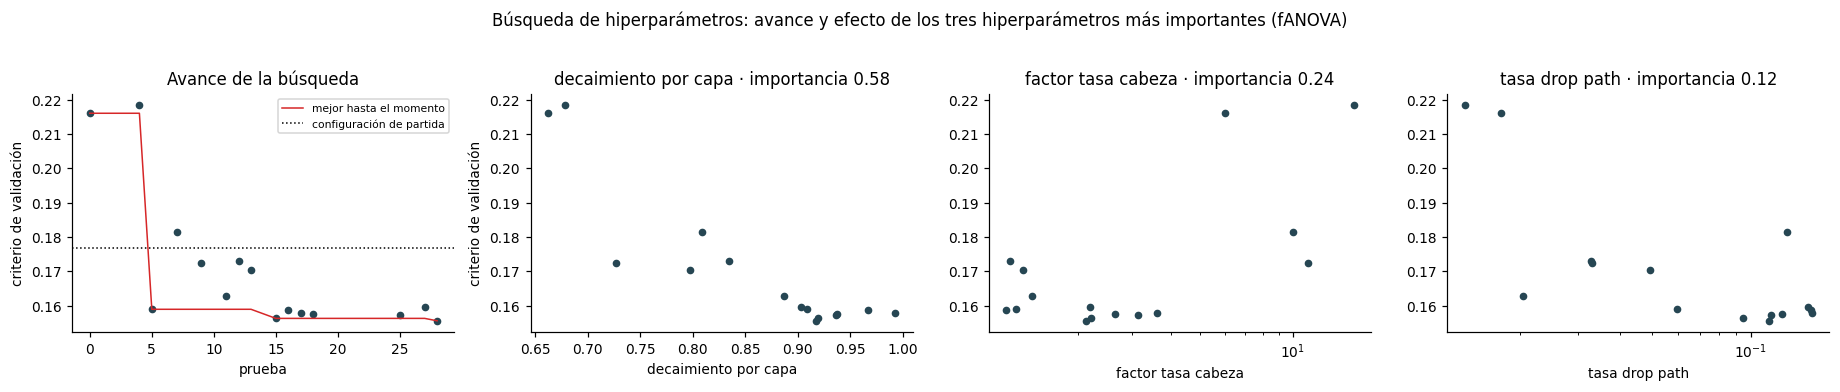

In [9]:
IMPORTANCIA_HIPERPARAMETROS = busqueda.importancia_hiperparametros(ESTUDIO)
grafica_hiperparametros(PRUEBAS, IMPORTANCIA_HIPERPARAMETROS, referencia=min(f["MSE_normalizado_medio"] for f in FILAS_BASE.values()),
                        titulo="Búsqueda de hiperparámetros: avance y efecto de los tres hiperparámetros más importantes (fANOVA)")

La búsqueda probó 30 configuraciones en 50 minutos, y la poda detuvo 15 de ellas antes de terminar sus 12 épocas. Desde la prueba 5 el criterio ya estaba por debajo del de la configuración de partida (0.177, línea punteada), y la mejor prueba llegó a 0.156. Las diez mejores pruebas coinciden en varias decisiones: todas usan solo la imagen, los pesos de ImageNet-1k y la pérdida MSE, con tasas de aprendizaje del extractor de 3 a 5 × 10⁻⁴, entre tres y cinco veces la de partida. Ninguna usa los pesos de ImageNet-22k que recomiendan los autores para imágenes naturales, ni los destilados de DINOv3.

Según fANOVA, el hiperparámetro que más pesa es el decaimiento de la tasa por capa (importancia 0.58). Las mejores pruebas usan valores de 0.88 a 0.99, es decir, casi la misma tasa en todas las capas, mientras que con 0.65 a 0.70 el criterio sube a 0.22. Un decaimiento fuerte protege a las primeras capas, que en ImageNet aprendieron bordes y texturas de fotografías; que aquí convenga lo contrario indica que las imágenes de galaxias en g, r y z son lo bastante distintas como para que también esas capas tengan que adaptarse. Le siguen el factor de la tasa de la cabeza (importancia 0.24), que funciona mejor entre 1 y 4 veces la tasa del extractor, y el *drop path* (0.12), con los mejores valores cerca de 0.1.

Las pruebas de la búsqueda usan pocas épocas, así que su ordenamiento puede cambiar al entrenar más tiempo. Por eso reentrenamos las mejores configuraciones con todas las épocas y la semilla 42, elegimos la mejor por el criterio de validación y la entrenamos después con las otras dos semillas.

In [10]:
mejores = PRUEBAS[PRUEBAS.estado == "complete"].head(FINALISTAS)
claves = ["variante_entrada", "tasa_extractor", "factor_tasa_cabeza", "decaimiento_pesos", "decaimiento_por_capa", "tasa_drop_path",
          "pesos", "perdida", "epocas_calentamiento"]
CORRIDAS_FINALISTAS, CONFIGURACIONES_FINALISTAS = [], []
for _, prueba_elegida in mejores.iterrows():
    espec, config, variables = configuracion_desde({k: prueba_elegida[k] for k in claves}, EPOCAS, SEMILLAS[0])
    CONFIGURACIONES_FINALISTAS.append((espec, config, variables))
    CORRIDAS_FINALISTAS.append(experimento.ejecutar_corrida(CONTEXTO, CARPETA_MODELO, f"finalista{int(prueba_elegida.prueba)}", espec,
                                                            config, ENTRADA_BASE, DISPOSITIVO, variables, registro=registro_compacto))
FINALISTAS_TABLA = pd.DataFrame([{"prueba": int(p.prueba), f"criterio en la búsqueda ({EPOCAS_BUSQUEDA} épocas)": p.criterio_validacion,
                                  "criterio con todas las épocas": r.resumen["mejor_criterio_validacion"],
                                  "mejor época": r.resumen["mejor_epoca"], **{k: p[k] for k in claves}}
                                 for (_, p), r in zip(mejores.iterrows(), CORRIDAS_FINALISTAS)])
display(FINALISTAS_TABLA.round(5))
posicion = int(np.argmin([r.resumen["mejor_criterio_validacion"] for r in CORRIDAS_FINALISTAS]))
CORRIDA_GANADORA = CORRIDAS_FINALISTAS[posicion]
espec_ganadora, config_ganadora, variables_ganadoras = CONFIGURACIONES_FINALISTAS[posicion]
VARIANTE_AJUSTADA = str(mejores.iloc[posicion].variante_entrada)
CORRIDAS_AJUSTADAS = [CORRIDA_GANADORA] + [
    experimento.ejecutar_corrida(CONTEXTO, CARPETA_MODELO, CORRIDA_GANADORA.identificador.split("_semilla")[0], espec_ganadora,
                                 replace(config_ganadora, semilla=s), ENTRADA_BASE, DISPOSITIVO, variables_ganadoras,
                                 registro=registro_compacto) for s in SEMILLAS[1:]]
FILA_AJUSTADA, _ = resumen_corridas(CORRIDAS_AJUSTADAS, f"3 · ConvNeXt-Tiny ajustado, {VARIANTE_AJUSTADA}")
base_misma_variante = CORRIDAS_BASE[VARIANTE_AJUSTADA]
print(f"Configuración ajustada ({VARIANTE_AJUSTADA}): {FILA_AJUSTADA['MSE_normalizado_medio']:.4f} ± {FILA_AJUSTADA['desviacion_entre_semillas']:.4f}"
      f" · base con la misma entrada: {FILAS_BASE[VARIANTE_AJUSTADA]['MSE_normalizado_medio']:.4f}")

filas = []
for base_corrida, ajustada in zip(base_misma_variante, CORRIDAS_AJUSTADAS):
    pb = experimento.predicciones_originales(CONTEXTO, base_corrida, "Validation", DISPOSITIVO)
    pa = experimento.predicciones_originales(CONTEXTO, ajustada, "Validation", DISPOSITIVO)
    for k, t in enumerate(OBJETIVOS):
        d, lo, hi = evaluacion.diferencia_pareada_rmse(y_validacion[:, k], pa[:, k], pb[:, k], n_remuestreos=N_REMUESTREOS)
        filas.append({"semilla": ajustada.resumen["configuracion"]["semilla"], "propiedad": CORTO[t], "ΔRMSE (ajustada − base)": d,
                      "IC 95 %": f"[{lo:+.3f}, {hi:+.3f}]", "veredicto": evaluacion.veredicto(lo, hi, MARGEN[CORTO[t]])})
display(pd.DataFrame(filas).set_index(["propiedad", "semilla"]).round(4))

época   5 · pérdida 0.1863 · validación 0.1839  ← mejor · 12 s
época  10 · pérdida 0.1358 · validación 0.1791 · 12 s
época  15 · pérdida 0.1003 · validación 0.1758 · 12 s
época  20 · pérdida 0.0651 · validación 0.1731 · 12 s
época  25 · pérdida 0.0456 · validación 0.1750 · 12 s
época  30 · pérdida 0.0407 · validación 0.1757 · 12 s
época   5 · pérdida 0.1848 · validación 0.2007 · 12 s
época  10 · pérdida 0.1393 · validación 0.1788 · 12 s
época  15 · pérdida 0.0991 · validación 0.1780 · 12 s
época  20 · pérdida 0.0606 · validación 0.1696 · 12 s
época  25 · pérdida 0.0387 · validación 0.1714 · 12 s
época  30 · pérdida 0.0327 · validación 0.1711 · 12 s
época   5 · pérdida 0.1817 · validación 0.1896  ← mejor · 12 s
época  10 · pérdida 0.1344 · validación 0.1742 · 12 s
época  15 · pérdida 0.0969 · validación 0.1722 · 12 s
época  20 · pérdida 0.0618 · validación 0.1671 · 12 s
época  25 · pérdida 0.0431 · validación 0.1663 · 12 s
época  30 · pérdida 0.0391 · validación 0.1692 · 12 s


,prueba,criterio en la búsqueda (12 épocas),criterio con todas las épocas,mejor época,variante_entrada,tasa_extractor,factor_tasa_cabeza,decaimiento_pesos,decaimiento_por_capa,tasa_drop_path,pesos,perdida,epocas_calentamiento
0,28,0.1556,0.1685,18,solo imagen,0.0004,2.1179,0.0274,0.9168,0.1132,convnext_tiny.fb_in1k,mse,2
1,15,0.1563,0.1663,18,solo imagen,0.0005,2.2043,0.1408,0.9193,0.0950,convnext_tiny.fb_in1k,mse,2
2,25,0.1573,0.1661,14,solo imagen,0.0004,3.1360,0.0401,0.9361,0.1148,convnext_tiny.fb_in1k,mse,1


época   5 · pérdida 0.1782 · validación 0.2030 · 12 s
época  10 · pérdida 0.1373 · validación 0.1690  ← mejor · 12 s
época  15 · pérdida 0.0939 · validación 0.1683 · 12 s
época  20 · pérdida 0.0597 · validación 0.1742 · 12 s
época  25 · pérdida 0.0428 · validación 0.1725 · 12 s
época  30 · pérdida 0.0373 · validación 0.1729 · 12 s
época   5 · pérdida 0.1822 · validación 0.1844  ← mejor · 12 s
época  10 · pérdida 0.1354 · validación 0.1692 · 12 s
época  15 · pérdida 0.0959 · validación 0.1719 · 12 s
época  20 · pérdida 0.0646 · validación 0.1790 · 12 s
época  25 · pérdida 0.0441 · validación 0.1695 · 12 s
época  30 · pérdida 0.0387 · validación 0.1722 · 12 s
Configuración ajustada (solo imagen): 0.1625 ± 0.0031 · base con la misma entrada: 0.1769


,,ΔRMSE (ajustada − base),IC 95 %,veredicto
propiedad,semilla,,,
M*,42,0.0020,"[-0.007, +0.011]",equivalente
SFR,42,-0.0329,"[-0.063, -0.002]",mejor
D4000,42,-0.0032,"[-0.006, -0.000]",mejor
M*,7,-0.0088,"[-0.016, -0.001]",mejor
SFR,7,-0.0348,"[-0.062, -0.009]",mejor
D4000,7,-0.0033,"[-0.007, +0.000]",equivalente
M*,2026,-0.0081,"[-0.015, -0.000]",mejor
SFR,2026,-0.0331,"[-0.060, -0.009]",mejor
D4000,2026,-0.0015,"[-0.004, +0.001]",equivalente


Al reentrenar las tres mejores configuraciones con 30 épocas, su criterio empeora de 0.156–0.157 a 0.166–0.169, y el orden cambia: la prueba 25, tercera en la búsqueda, queda primera con 0.166. Las curvas explican la diferencia. Con la tasa de aprendizaje más alta, la pérdida de entrenamiento baja hasta 0.03 o 0.04, contra 0.07 en el modelo base, mientras que el error de validación deja de mejorar hacia las épocas 15 a 20. Con 12 épocas, el programa coseno lleva la tasa a cero antes de que el modelo empiece a memorizar; con 30, el modelo pasa más tiempo con tasas altas y se sobreajusta. Mantuvimos las 30 épocas del protocolo para que el modelo sea comparable con los demás del avance, pero el resultado sugiere que un programa más corto daría un modelo mejor y más barato de entrenar.

Aun así, la configuración ajustada mejora a la base. Con las tres semillas, el criterio baja de 0.177 a 0.163 ± 0.003, una reducción de 8 %. La comparación pareada muestra dónde está la ganancia: la SFR mejora en las tres semillas (entre 0.033 y 0.035 dex), la masa en dos de tres (unos 0.008 dex) y D4000 en una; en los demás casos la diferencia es equivalente a cero. Esta comparación usa las mismas galaxias de validación con las que se eligió la configuración, así que es algo optimista. El conjunto de prueba (sección 11) da la medida independiente.

## 8. Comparación en validación

La tabla ordena los modelos por la métrica principal del protocolo común, el promedio del MSE normalizado, y muestra además el RMSE, el MAE, el sesgo y el R² de cada propiedad, el tiempo de entrenamiento y el número de parámetros entrenables. En los modelos con el extractor congelado, el tiempo incluye la extracción de las representaciones.

Como referencia incluimos los modelos que el equipo ya evaluó con el mismo protocolo, con la media de sus tres semillas:

- **Comparables:** las variantes F y G de ResNet50 (sin redshift) y el baseline del Avance 3 (cadena de ResNet50, solo imagen), recalculado sobre nuestras galaxias de validación. Igual que nuestros modelos, solo necesitan la imagen al predecir.
- **Techo, no comparables:** la variante E de ResNet50 y el SVR, que reciben el **redshift medido**. Ese dato no estará disponible en la práctica, así que no compiten; indican cuánto se pierde por no tenerlo.

,modelo,entradas,solo_imagen_al_predecir,MSE_normalizado_medio,desviacion_entre_semillas,RMSE M*,RMSE SFR,RMSE D4000,MAE M*,MAE SFR,MAE D4000,sesgo M*,sesgo SFR,sesgo D4000,R2 M*,R2 SFR,R2 D4000,minutos_entrenamiento,parametros_entrenables_M,semillas,fuente
1,Techo · ResNet50 multitarea con redshift medid...,imagen + redshift medido,no,0.1269,NaN,0.1093,0.5922,0.0736,0.0829,0.3966,0.0529,0.0029,-0.0166,0.0078,0.9722,0.7409,0.9024,NaN,NaN,3,"reportado (1,261 galaxias)"
2,"Baseline del Avance 3 · cadena de ResNet50, so...",solo imagen,sí,0.1585,NaN,0.2166,0.6080,0.0724,0.1623,0.4414,0.0535,-0.0121,-0.0199,-0.0024,0.8908,0.7269,0.9056,NaN,NaN,1,recalculado
3,"3 · ConvNeXt-Tiny ajustado, solo imagen",solo imagen,sí,0.1625,0.0031,0.2281,0.6069,0.0728,0.1742,0.4315,0.0516,-0.0105,-0.0227,0.0064,0.8789,0.7279,0.9045,5.9902,28.4115,3,este cuaderno
4,"3 · ConvNeXt-Tiny base, solo imagen",solo imagen,sí,0.1769,0.0019,0.2331,0.6404,0.0755,0.1799,0.4562,0.0538,0.0165,0.0129,0.0094,0.8737,0.6970,0.8974,6.1355,28.4115,3,este cuaderno
5,"1 · ResNet50 multitarea, GRZ, MSE, sin redshif...",solo imagen,sí,0.1781,NaN,0.2368,0.6413,0.0748,0.1811,0.4587,0.0540,-0.0068,0.0315,-0.0004,0.8696,0.6960,0.8992,NaN,NaN,3,"reportado (1,261 galaxias)"
6,"3 · ConvNeXt-Tiny base, imagen + redshift esti...",imagen + redshift predicho,sí,0.1781,0.0048,0.2354,0.6392,0.0763,0.1803,0.4570,0.0545,0.0021,0.0179,0.0109,0.8710,0.6982,0.8952,5.9978,28.4123,3,este cuaderno
7,"1 · ResNet50 multitarea, GRZ, Huber, sin redsh...",solo imagen,sí,0.1795,NaN,0.2344,0.6484,0.0749,0.1789,0.4593,0.0543,-0.0187,0.0058,-0.0010,0.8722,0.6893,0.8990,NaN,NaN,3,"reportado (1,261 galaxias)"
8,Techo · SVR con redshift medido (modelo 2 del ...,imagen + redshift medido,no,0.4421,NaN,0.2661,0.9828,0.1611,0.1995,0.7599,0.1259,-0.0049,0.0345,-0.0019,0.8353,0.2865,0.5326,NaN,NaN,1,"reportado (1,261 galaxias)"


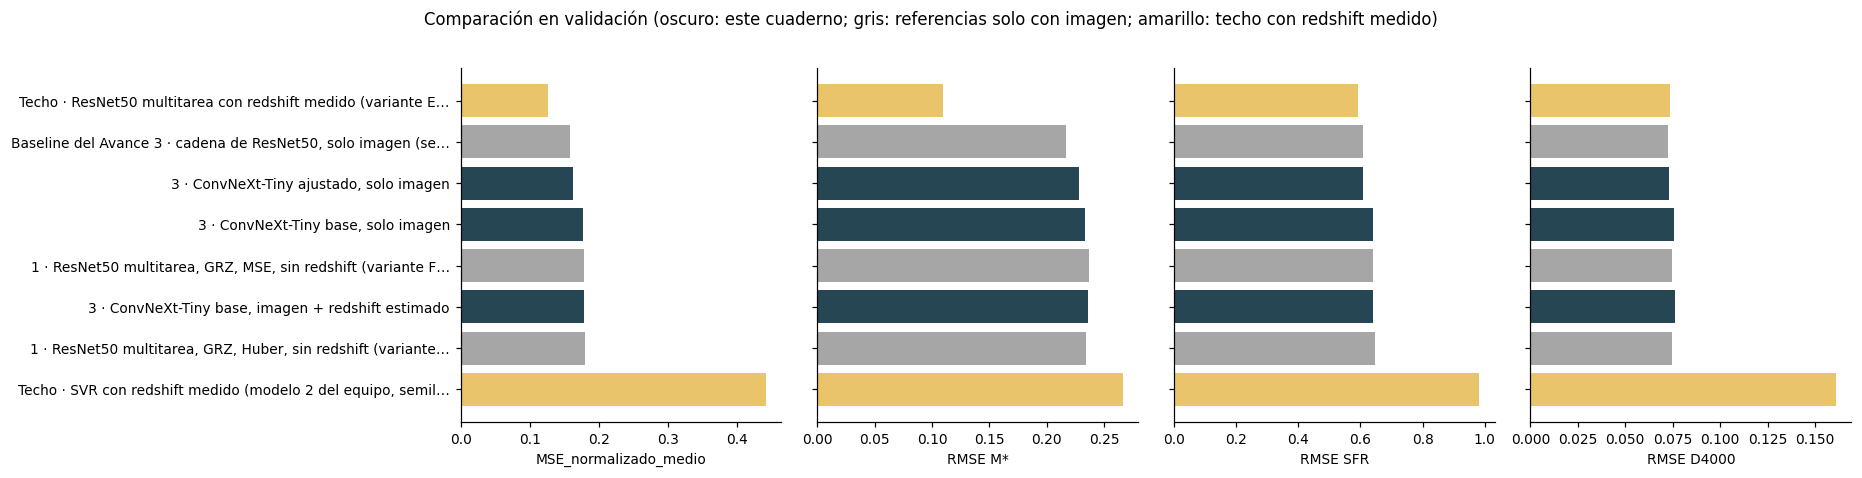

In [11]:
def _referencia(modelo, semillas, mse, rmse, mae, sesgo, r2, solo_imagen, fuente):
    fila = {"modelo": modelo, "entradas": "solo imagen" if solo_imagen == "sí" else "imagen + redshift medido",
            "solo_imagen_al_predecir": solo_imagen, "semillas": semillas, "MSE_normalizado_medio": mse, "fuente": fuente}
    for nombre, valores in (("RMSE", rmse), ("MAE", mae), ("sesgo", sesgo), ("R2", r2)):
        for corto, v in zip(("M*", "SFR", "D4000"), valores):
            fila[f"{nombre} {corto}"] = v
    return fila

REFERENCIAS = pd.DataFrame([
    _referencia("1 · ResNet50 multitarea, GRZ, Huber, sin redshift (variante G del equipo)", 3, 0.179510,
                (0.234420, 0.648439, 0.074901), (0.178870, 0.459307, 0.054264), (-0.018683, 0.005795, -0.000994),
                (0.872191, 0.689332, 0.898955), "sí", "reportado (1,261 galaxias)"),
    _referencia("1 · ResNet50 multitarea, GRZ, MSE, sin redshift (variante F del equipo)", 3, 0.178092,
                (0.236772, 0.641321, 0.074808), (0.181068, 0.458739, 0.054033), (-0.006764, 0.031536, -0.000373),
                (0.869582, 0.695999, 0.899214), "sí", "reportado (1,261 galaxias)"),
    _referencia("Techo · ResNet50 multitarea con redshift medido (variante E del equipo)", 3, 0.126881,
                (0.109265, 0.592216, 0.073610), (0.082881, 0.396620, 0.052947), (0.002940, -0.016601, 0.007759),
                (0.972233, 0.740901, 0.902414), "no", "reportado (1,261 galaxias)"),
    _referencia("Techo · SVR con redshift medido (modelo 2 del equipo, semilla 42)", 1, 0.442091,
                (0.266115, 0.982788, 0.161113), (0.199477, 0.759899, 0.125858), (-0.004865, 0.034490, -0.001860),
                (0.835294, 0.286476, 0.532613), "no", "reportado (1,261 galaxias)")])

def fila_baseline_avance3():
    # Cadena de ResNet50 del Avance 3 (solo imagen), recalculada sobre nuestras galaxias de validación.
    ruta = BASE_DRIVE / "resultados_katachi_fits" / "avance3" / "predicciones_B2_seed42.csv"
    if not ruta.exists():
        return None, None
    pred = pd.read_csv(ruta, dtype={"mangaid": str}).set_index("mangaid")
    ids = MUESTRA.mangaid.iloc[INDICES["Validation"]]
    p = pred.reindex(ids)[[f"pred_{t}" for t in OBJETIVOS]].to_numpy(float)
    if not np.isfinite(p).all():
        return None, None
    tabla = experimento.tabla_corrida(CONTEXTO, p, "Validation")
    fila = {"modelo": "Baseline del Avance 3 · cadena de ResNet50, solo imagen (semilla 42, con TTA)", "entradas": "solo imagen",
            "solo_imagen_al_predecir": "sí", "semillas": 1, "MSE_normalizado_medio": tabla.MSE_normalizado.mean(), "fuente": "recalculado"}
    for _, r in tabla.iterrows():
        for m in ("RMSE", "MAE", "sesgo", "R2"):
            fila[f"{m} {CORTO[r.objetivo]}"] = r[m]
    return fila, p

FILA_AVANCE3, PRED_AVANCE3_VALIDACION = fila_baseline_avance3()
filas = [*FILAS_BASE.values(), FILA_AJUSTADA]
COMPARATIVA = pd.concat([pd.DataFrame(filas).assign(fuente="este cuaderno"), REFERENCIAS,
                         pd.DataFrame([FILA_AVANCE3]) if FILA_AVANCE3 else None]).sort_values("MSE_normalizado_medio").reset_index(drop=True)
COMPARATIVA.index = COMPARATIVA.index + 1
columnas = ["modelo", "entradas", "solo_imagen_al_predecir", "MSE_normalizado_medio", "desviacion_entre_semillas", "RMSE M*", "RMSE SFR",
            "RMSE D4000", "MAE M*", "MAE SFR", "MAE D4000", "sesgo M*", "sesgo SFR", "sesgo D4000", "R2 M*", "R2 SFR", "R2 D4000",
            "minutos_entrenamiento", "parametros_entrenables_M", "semillas", "fuente"]
display(COMPARATIVA[[c for c in columnas if c in COMPARATIVA]].round(4))

fig, ejes = plt.subplots(1, 4, figsize=(17, 0.6 + 0.45 * len(COMPARATIVA)), sharey=True)
etiquetas = [m if len(m) < 62 else m[:59] + "…" for m in COMPARATIVA.modelo]
colores = ["#264653" if f == "este cuaderno" else ("#e9c46a" if s == "no" else "0.65")
           for f, s in zip(COMPARATIVA.fuente, COMPARATIVA.solo_imagen_al_predecir)]
for eje, columna in zip(ejes, ["MSE_normalizado_medio", "RMSE M*", "RMSE SFR", "RMSE D4000"]):
    eje.barh(etiquetas, COMPARATIVA[columna], color=colores); eje.set_xlabel(columna)
ejes[0].invert_yaxis()
plt.suptitle("Comparación en validación (oscuro: este cuaderno; gris: referencias solo con imagen; amarillo: techo con redshift medido)", y=1.02)
plt.tight_layout(); plt.show()

En validación, ConvNeXt-Tiny ajustado (0.163) es el mejor de los modelos individuales que usan solo la imagen, por delante de las variantes F y G de ResNet50 (0.178 y 0.180). La ventaja viene sobre todo de la SFR, cuyo RMSE baja de 0.641 a 0.607 dex y cuyo R² sube de 0.70 a 0.73. En la masa y en D4000 las diferencias son menores: de 0.006 a 0.009 dex y de 0.002, respectivamente.

El baseline del Avance 3 queda ligeramente mejor (0.159), pero hay que leerlo con dos precauciones. Es una sola semilla, y es una cadena de tres ResNet50, una por propiedad, en la que cada red recibe las predicciones de las anteriores, con unos 70 M de parámetros en total. Con una sola red de 28 M de parámetros, ConvNeXt iguala a la cadena en SFR y D4000 y queda 0.011 dex atrás en la masa.

Los dos techos muestran cuánto vale el redshift medido. La variante E del modelo 1 baja el RMSE de la masa a 0.109 dex, menos de la mitad que cualquier modelo solo con imagen, mientras que en SFR y D4000 la mejora es pequeña. Es lo esperado: la masa depende de la luminosidad, y para calcular la luminosidad hace falta la distancia, mientras que D4000 es un cociente de flujos que no depende de ella. El SVR, aun con el redshift medido, queda muy por detrás de todos los modelos.

In [12]:
# Elección dentro de este cuaderno: la configuración con menor criterio medio entre semillas.
CANDIDATAS = {f"configuración base, {v}": (FILAS_BASE[v], CORRIDAS_BASE[v]) for v in VARIANTES_ENTRADA}
CANDIDATAS[f"configuración ajustada, {VARIANTE_AJUSTADA}"] = (FILA_AJUSTADA, CORRIDAS_AJUSTADAS)
NOMBRE_ELEGIDA = min(CANDIDATAS, key=lambda k: CANDIDATAS[k][0]["MSE_normalizado_medio"])
CORRIDAS_ELEGIDAS = CANDIDATAS[NOMBRE_ELEGIDA][1]
display(pd.DataFrame({k: {"MSE normalizado medio": v[0]["MSE_normalizado_medio"], "desviación entre semillas": v[0]["desviacion_entre_semillas"]}
                      for k, v in CANDIDATAS.items()}).T.round(4))
print("Configuración que representa al modelo 3:", NOMBRE_ELEGIDA)

,MSE normalizado medio,desviación entre semillas
"configuración base, solo imagen",0.1769,0.0019
"configuración base, imagen + redshift estimado",0.1781,0.0048
"configuración ajustada, solo imagen",0.1625,0.0031


Configuración que representa al modelo 3: configuración ajustada, solo imagen


## 9. Diagnóstico del modelo elegido

Revisamos el ajuste del modelo elegido con tres herramientas: la evolución del error por época en entrenamiento y validación, la comparación de las métricas entre las dos particiones y los residuos (predicción − etiqueta) frente al valor real y al redshift. Una brecha grande entre entrenamiento y validación indica sobreajuste; errores altos en ambas, junto con una pendiente negativa del residuo frente al valor real (regresión a la media), indican subajuste. El residuo frente al redshift medido muestra si el modelo todavía se equivoca según la distancia, el problema principal que encontramos en el Avance 3.

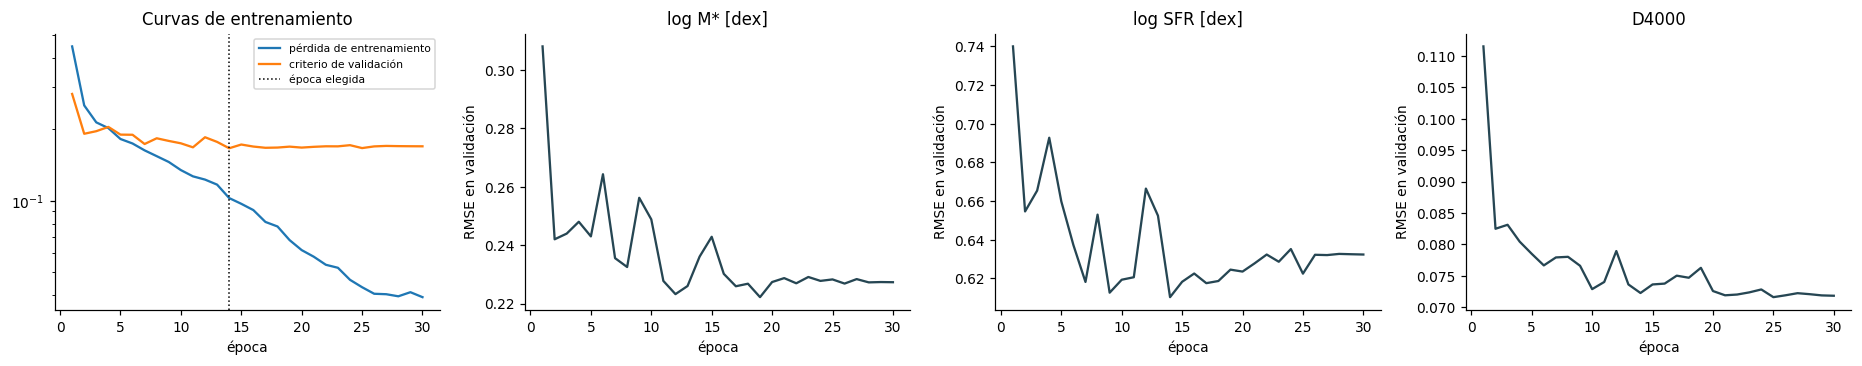

RMSE              sesgo            sigma_NMAD                      cociente           referencia
particion   Train Validation   Train Validation      Train Validation Validation / Train error de la etiqueta
objetivo                                                                                                     
log_mstar  0.1673     0.2361 -0.0552    -0.0492     0.1517     0.2063             1.4113               0.0759
log_sfr    0.4383     0.6103 -0.0750    -0.0568     0.3048     0.4307             1.3924               0.0758
d4000      0.0572     0.0723  0.0037     0.0063     0.0465     0.0557             1.2641               0.0163

In [13]:
CORRIDA_ELEGIDA = CORRIDAS_ELEGIDAS[0]
historial = CORRIDA_ELEGIDA.historial
if "perdida_entrenamiento" not in historial:
    print("El modelo elegido usa el extractor congelado: solo la cabeza aprendió y no hay curvas de entrenamiento de la imagen.")
else:
  fig, ejes = plt.subplots(1, 4, figsize=(17, 3.4))
  ejes[0].plot(historial.epoca, historial.perdida_entrenamiento, label="pérdida de entrenamiento")
  ejes[0].plot(historial.epoca, historial.criterio_validacion, label="criterio de validación")
  ejes[0].axvline(CORRIDA_ELEGIDA.resumen["mejor_epoca"], color="k", ls=":", lw=1, label="época elegida")
  ejes[0].set(xlabel="época", yscale="log", title="Curvas de entrenamiento"); ejes[0].legend(fontsize=7)
  for k, (eje, t) in enumerate(zip(ejes[1:], OBJETIVOS)):
      eje.plot(historial.epoca, np.sqrt(historial[f"mse_validacion_salida{k}"]) * CONTEXTO.desviacion_etiquetas_entrenamiento[k], color="#264653")
      eje.set(xlabel="época", ylabel="RMSE en validación", title=NOMBRES[t])
  plt.tight_layout(); plt.show()

ajuste = pd.concat([metricas_corrida(CORRIDA_ELEGIDA, p)[0] for p in ("Train", "Validation")])
ajuste = ajuste.pivot_table(index="objetivo", columns="particion", values=["RMSE", "sesgo", "sigma_NMAD"]).reindex(list(OBJETIVOS))
ajuste[("cociente", "Validation / Train")] = ajuste[("RMSE", "Validation")] / ajuste[("RMSE", "Train")]
ajuste[("referencia", "error de la etiqueta")] = [MUESTRA[f"error_{t}"].median() for t in OBJETIVOS]
display(ajuste.round(4))

La curva del modelo elegido (semilla 42) muestra la separación descrita en la sección 7: la pérdida de entrenamiento sigue bajando hasta la época 30, mientras que el criterio de validación se estabiliza después de la época 14, que es la que se conserva. Los errores de cada propiedad en validación oscilan durante las primeras diez épocas y se estabilizan cuando baja la tasa de aprendizaje.

El error de validación es entre 1.26 y 1.41 veces el de entrenamiento, así que hay un sobreajuste moderado, mayor en masa y SFR que en D4000. Aun en entrenamiento el error queda muy por encima del error de medición de las etiquetas (0.17 contra 0.08 dex en la masa), de modo que el modelo no llega a memorizarlas. La semilla 42 tiene además un sesgo de −0.05 dex en la masa, igual en las dos particiones y mayor que el promedio de las tres semillas (−0.01); por eso es la semilla con mayor error en la masa, también en la prueba.

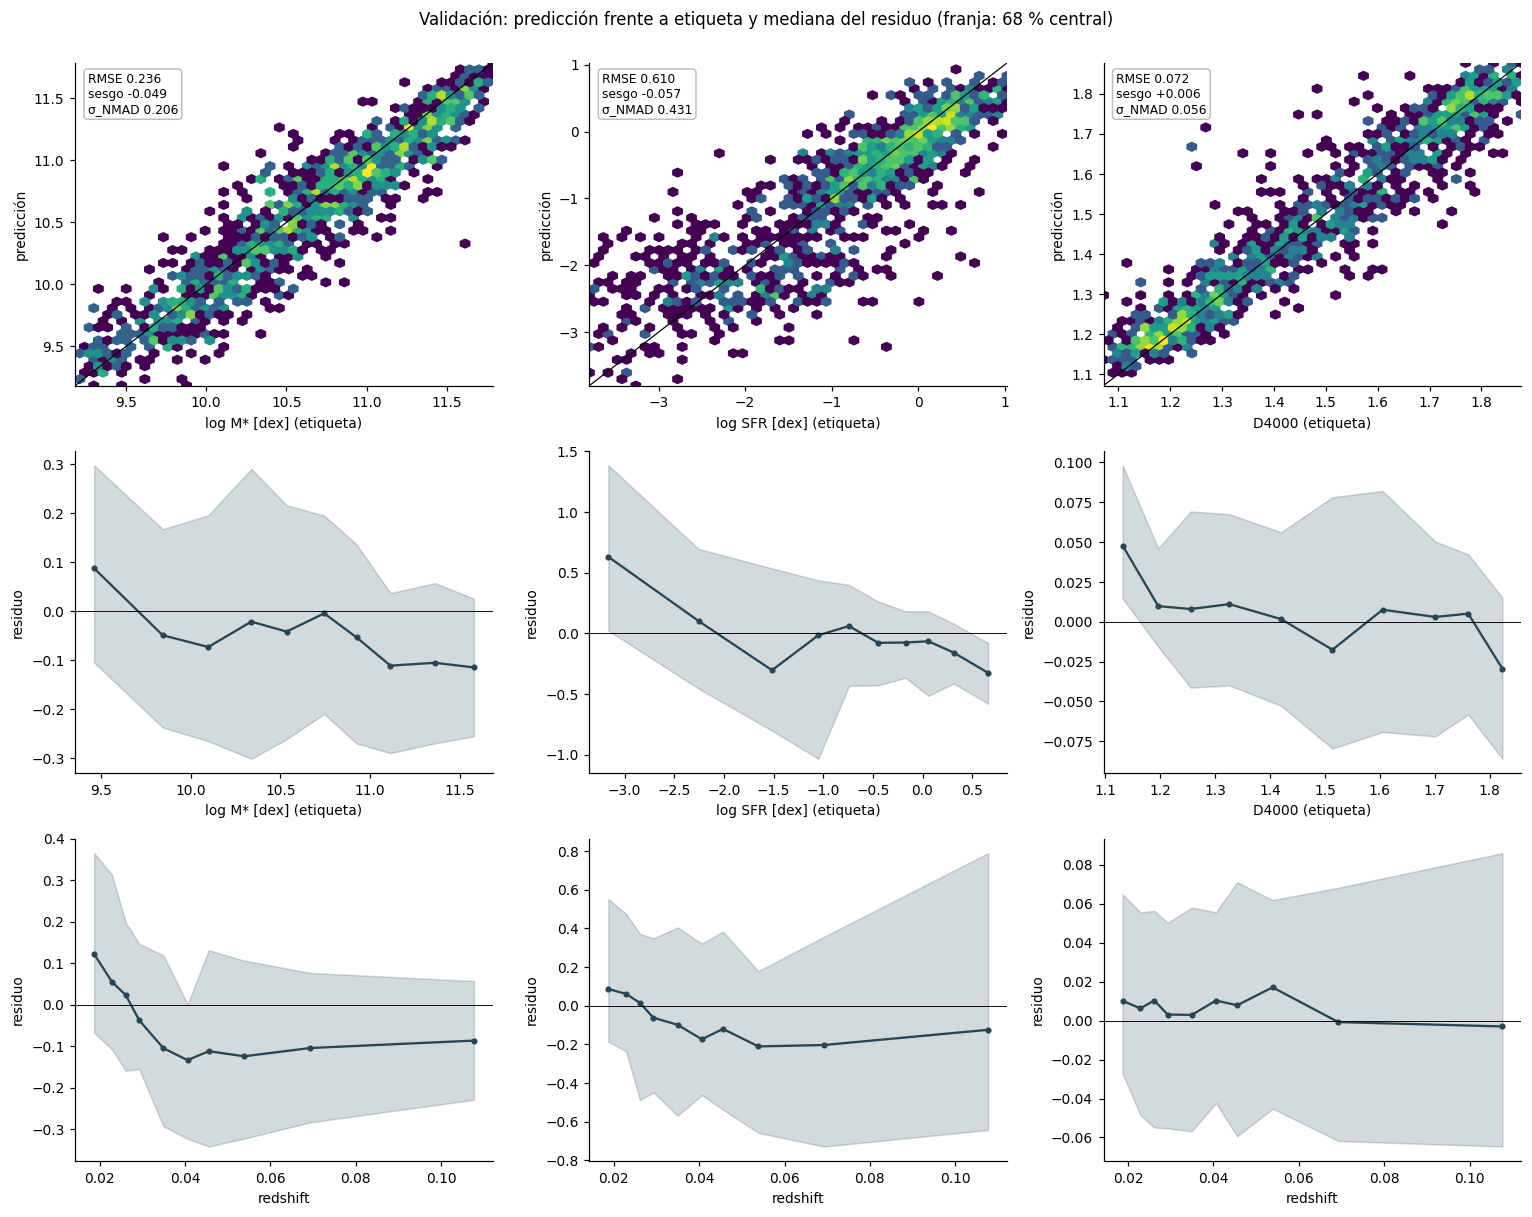

RMSE             sesgo          
grupo     apagada formadora apagada formadora
objetivo                                     
log_mstar  0.2249    0.2485 -0.0610   -0.0354
log_sfr    0.7509    0.3891  0.0123   -0.1366
d4000      0.0844    0.0550 -0.0026    0.0167

In [14]:
PRED_VALIDACION = experimento.predicciones_originales(CONTEXTO, CORRIDA_ELEGIDA, "Validation", DISPOSITIVO)
Y_VALIDACION = CONTEXTO.etiquetas("Validation")
z_validacion = MUESTRA.redshift.to_numpy()[INDICES["Validation"]]

def mediana_movil(x, r, n=10):
    bordes = np.quantile(x, np.linspace(0, 1, n + 1)); centro, med, p16, p84 = [], [], [], []
    for a, b in zip(bordes[:-1], bordes[1:]):
        s = (x >= a) & (x <= b)
        if s.sum() >= 10:
            centro.append(np.median(x[s])); med.append(np.median(r[s])); p16.append(np.percentile(r[s], 16)); p84.append(np.percentile(r[s], 84))
    return map(np.array, (centro, med, p16, p84))

fig, ejes = plt.subplots(3, 3, figsize=(14, 11))
for k, t in enumerate(OBJETIVOS):
    y, p = Y_VALIDACION[:, k], PRED_VALIDACION[:, k]
    lim = np.percentile(np.r_[y, p], [0.5, 99.5])
    ejes[0, k].hexbin(y, p, gridsize=45, cmap="viridis", mincnt=1, bins="log", extent=(*lim, *lim))
    ejes[0, k].plot(lim, lim, "k-", lw=0.8)
    m = evaluacion.metricas(y, p)
    ejes[0, k].text(0.03, 0.97, f"RMSE {m['RMSE']:.3f}\nsesgo {m['sesgo']:+.3f}\nσ_NMAD {m['sigma_NMAD']:.3f}", transform=ejes[0, k].transAxes,
                    va="top", fontsize=8, bbox=dict(boxstyle="round", facecolor="white", alpha=0.85, edgecolor="0.7"))
    ejes[0, k].set(xlim=lim, ylim=lim, xlabel=f"{NOMBRES[t]} (etiqueta)", ylabel="predicción")
    for fila, x, nombre_x in ((1, y, f"{NOMBRES[t]} (etiqueta)"), (2, z_validacion, "redshift")):
        cx, med, p16, p84 = mediana_movil(x, p - y)
        ejes[fila, k].plot(cx, med, "o-", ms=3, color="#264653"); ejes[fila, k].fill_between(cx, p16, p84, color="#264653", alpha=0.2)
        ejes[fila, k].axhline(0, color="k", lw=0.6); ejes[fila, k].set(xlabel=nombre_x, ylabel="residuo")
plt.suptitle("Validación: predicción frente a etiqueta y mediana del residuo (franja: 68 % central)", y=1.0); plt.tight_layout(); plt.show()

tipo_validacion = TIPO_GALAXIA[INDICES["Validation"]]
display(evaluacion.metricas_por_grupo(Y_VALIDACION, PRED_VALIDACION, tipo_validacion, OBJETIVOS)
        .pivot(index="objetivo", columns="grupo", values=["RMSE", "sesgo"]).reindex(list(OBJETIVOS)).round(4))

La primera fila confirma que las predicciones siguen la relación uno a uno en las tres propiedades. La segunda muestra una compresión hacia el centro, típica de la regresión: el modelo sobreestima la masa de las galaxias menos masivas (en unos 0.09 dex) y subestima la de las más masivas (en unos 0.11 dex). El efecto más fuerte está en la SFR más baja, donde las galaxias con log SFR ≈ −3 reciben 0.6 dex de más. En las galaxias apagadas la formación estelar casi no deja huella en la imagen, así que el modelo no distingue una SFR muy baja de una extremadamente baja. Lo mismo indica la tabla por tipo de galaxia: la SFR de las apagadas tiene casi el doble de error que la de las formadoras (0.75 contra 0.39 dex), y en las formadoras el modelo la subestima en 0.14 dex en promedio.

La tercera fila muestra el efecto de no conocer la distancia. En la masa, el residuo pasa de +0.12 dex en z ≈ 0.02 a cerca de −0.12 dex a partir de z ≈ 0.04: el modelo sobreestima la masa de las galaxias cercanas, que se ven más grandes y brillantes, y subestima la de las lejanas. La SFR muestra la misma tendencia, más débil. En D4000, que no depende de la distancia, el residuo es plano. Esta es la parte del error que corrige el redshift medido en la variante E y que el redshift estimado no alcanza a corregir.

## 10. ¿Qué información usa el modelo?

Medimos la importancia de cada entrada como el aumento del error cuando el modelo deja de recibirla, en las galaxias de validación. Quitamos una banda a la vez y una región de la galaxia a la vez (anillos en unidades del radio de mitad de luz) y, si el modelo usa el redshift estimado, lo revolvemos entre galaxias. Las bandas y las regiones se quitan en la imagen original, poniendo su flujo en el nivel del cielo (0, porque las imágenes de DESI tienen el cielo restado), y después la imagen pasa por la misma preparación que usa el modelo. Las imágenes modificadas son distintas de las que el modelo vio al entrenar, así que la prueba indica qué información usa, no qué información existe. Con la misma prueba en todos los modelos podemos comparar cómo razonan.

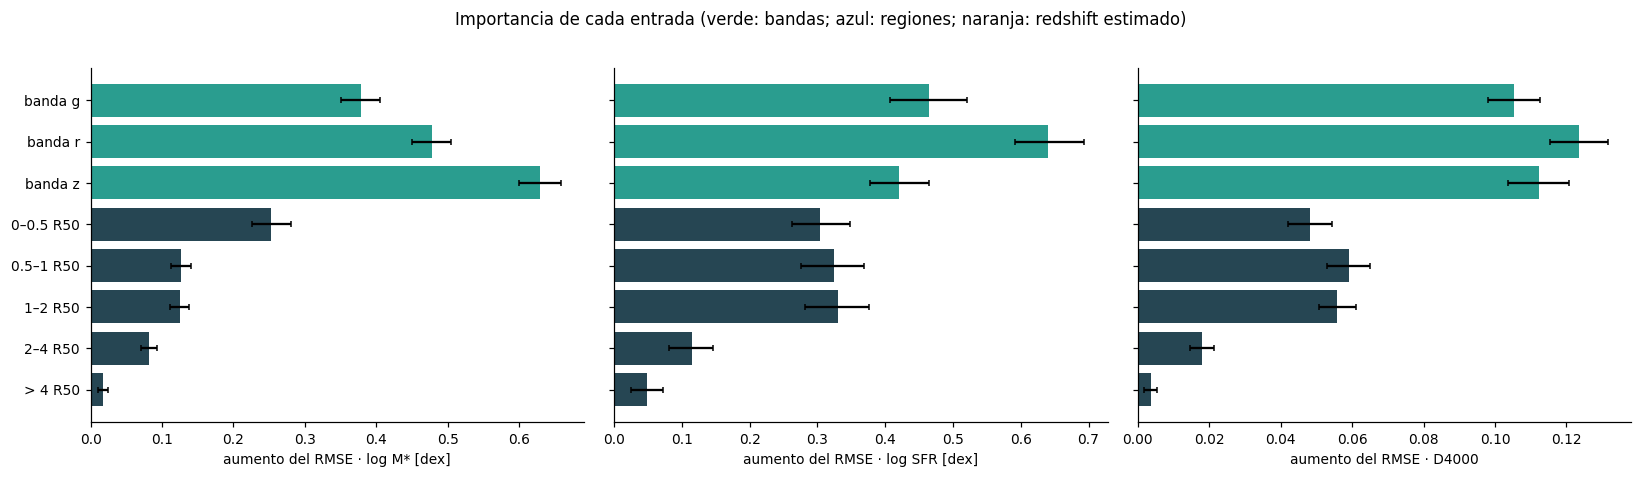

In [15]:
conjunto_validacion = experimento.conjunto_de(CONTEXTO, CORRIDA_ELEGIDA, "Validation", DISPOSITIVO)
radio_validacion = RADIO_MITAD_LUZ[INDICES["Validation"]]
base = CORRIDA_ELEGIDA.preparador
prediccion_base = CONTEXTO.a_escala_original(interpretacion.predecir_con_modificacion(CORRIDA_ELEGIDA.modelo, base, conjunto_validacion))
pruebas = [("banda", f"banda {nombre}", dict(banda=k)) for k, nombre in enumerate(("g", "r", "z"))]
pruebas += [("región", f"{a}–{b} R50" if np.isfinite(b) else f"> {a} R50", dict(anillo=(a, b), radio_mitad_luz_px=radio_validacion))
            for a, b in [(0, 0.5), (0.5, 1), (1, 2), (2, 4), (4, np.inf)]]
pruebas += [("variable escalar", f"{nombre} revuelto", dict(escalar_permutado=k, semilla=SEMILLAS[0]))
            for k, nombre in enumerate(CORRIDA_ELEGIDA.variables_escalares)]
filas = []
for tipo, nombre, argumentos in pruebas:
    p = CONTEXTO.a_escala_original(interpretacion.predecir_con_modificacion(CORRIDA_ELEGIDA.modelo, base, conjunto_validacion, **argumentos))
    for k, t in enumerate(OBJETIVOS):
        d, lo, hi = evaluacion.diferencia_pareada_rmse(Y_VALIDACION[:, k], p[:, k], prediccion_base[:, k], n_remuestreos=N_REMUESTREOS)
        filas.append({"tipo": tipo, "entrada quitada": nombre, "propiedad": CORTO[t], "aumento del RMSE": d, "lo": lo, "hi": hi})
IMPORTANCIA = pd.DataFrame(filas)
fig, ejes = plt.subplots(1, 3, figsize=(15, 4.2), sharey=True)
for eje, t in zip(ejes, OBJETIVOS):
    d = IMPORTANCIA[IMPORTANCIA.propiedad == CORTO[t]]
    colores = d.tipo.map({"banda": "#2a9d8f", "región": "#264653", "variable escalar": "#e76f51"})
    eje.barh(d["entrada quitada"], d["aumento del RMSE"], xerr=[d["aumento del RMSE"] - d.lo, d.hi - d["aumento del RMSE"]],
             color=colores, capsize=2)
    eje.axvline(0, color="k", lw=0.6); eje.set(xlabel=f"aumento del RMSE · {NOMBRES[t]}")
ejes[0].invert_yaxis(); plt.suptitle("Importancia de cada entrada (verde: bandas; azul: regiones; naranja: redshift estimado)", y=1.02)
plt.tight_layout(); plt.show()

Las tres bandas son necesarias: quitar cualquiera aumenta el RMSE de la masa entre 0.38 y 0.63 dex, varias veces su error actual. Para la masa, la banda más importante es z (+0.63 dex), la más roja, que sigue mejor a las estrellas viejas donde está la mayor parte de la masa. Para la SFR y para D4000 pesa más la banda r (+0.64 dex y +0.12). La magnitud de estas cifras se debe leer con cuidado: una imagen con una banda en cero es muy distinta de las que vio el modelo, así que indican cuánto depende el modelo de cada banda, no cuánta información aporta cada una por sí sola.

Por regiones, la masa depende sobre todo del centro de la galaxia (0 a 0.5 R50, +0.25 dex), donde se concentra la luz. La SFR usa por igual el centro y el disco hasta 2 R50 (+0.30 a +0.33 dex), lo que coincide con el Avance 3, donde la estructura del disco resultó la más informativa para la SFR. D4000 depende más de la zona entre 0.5 y 2 R50. Más allá de 4 R50 la oclusión casi no cambia el error en ninguna propiedad: el modelo usa la galaxia y no el fondo ni las fuentes vecinas.

## 11. Evaluación en el conjunto de prueba

Con el modelo, su configuración y sus semillas ya fijados en validación, registramos la elección y abrimos el conjunto de prueba **una sola vez**. El registro incluye una huella de las predicciones de validación: si el cuaderno se volviera a ejecutar con otro modelo, lo detectaría y advertiría que esa evaluación ya no es independiente.

Reportamos las métricas del protocolo común con la semilla 42 y la media de las tres semillas, con y sin promedio de las 8 simetrías de cada imagen (*test-time augmentation*, TTA). Además comparamos, galaxia por galaxia, con el baseline del Avance 3 y con las predicciones publicadas de Katachi (Alfonzo et al. 2024) en las mismas galaxias.

In [16]:
CORRIDAS_FINALES = CORRIDAS_ELEGIDAS
ELECCION = {"modelo": NOMBRE_MODELO, "descripcion": f'ConvNeXt-Tiny, {NOMBRE_ELEGIDA}', "corridas": [r.identificador for r in CORRIDAS_FINALES],
            "entradas": list(CORRIDAS_FINALES[0].variables_escalares), "commit": COMMIT}
experimento.registrar_eleccion_antes_de_prueba(CONTEXTO, CARPETA_MODELO / "registro_prueba.json", ELECCION,
                                               experimento.predicciones_originales(CONTEXTO, CORRIDAS_FINALES[0], "Validation", DISPOSITIVO))
Y_PRUEBA = CONTEXTO.etiquetas("Test")
tablas, PRED_PRUEBA = [], {}
for corrida in CORRIDAS_FINALES:
    semilla = corrida.resumen["configuracion"]["semilla"]
    for tta in (False, True):
        p = experimento.predicciones_originales(CONTEXTO, corrida, "Test", DISPOSITIVO, tta=tta)
        PRED_PRUEBA[(semilla, tta)] = p
        tablas.append(experimento.tabla_corrida(CONTEXTO, p, "Test", semilla=semilla, tta="sí" if tta else "no"))
METRICAS_PRUEBA = pd.concat(tablas)
resumen_prueba = (METRICAS_PRUEBA.groupby(["tta", "objetivo"], sort=False)[["RMSE", "MAE", "sesgo", "R2", "MSE_normalizado"]]
                  .agg(["mean", "std"]).round(4))
display(resumen_prueba)
for tta in ("no", "sí"):
    medio = METRICAS_PRUEBA[METRICAS_PRUEBA.tta == tta].groupby("semilla").MSE_normalizado.mean()
    print(f"MSE normalizado medio en prueba, TTA {tta}: {medio.mean():.4f} ± {medio.std(ddof=1) if len(medio) > 1 else float('nan'):.4f}")
if "redshift_predicho" in MUESTRA:
    idx = INDICES["Test"]
    print("Calidad del redshift estimado en prueba:",
          {k: round(v, 4) for k, v in metricas_redshift(MUESTRA.redshift.to_numpy()[idx], MUESTRA.redshift_predicho.to_numpy()[idx]).items()})

Elección registrada antes de abrir la prueba.


RMSE             MAE           sesgo              R2         MSE_normalizado        
                 mean     std    mean     std    mean     std    mean     std            mean     std
tta objetivo                                                                                         
no  log_mstar  0.2277  0.0126  0.1688  0.0104 -0.0237  0.0268  0.8671  0.0149          0.1242  0.0139
    log_sfr    0.6208  0.0067  0.4267  0.0071 -0.0341  0.0504  0.7386  0.0056          0.2858  0.0062
    d4000      0.0751  0.0023  0.0535  0.0011  0.0005  0.0014  0.9013  0.0061          0.0959  0.0059
sí  log_mstar  0.2214  0.0120  0.1644  0.0102 -0.0248  0.0266  0.8743  0.0138          0.1174  0.0129
    log_sfr    0.6092  0.0055  0.4188  0.0066 -0.0369  0.0477  0.7483  0.0045          0.2752  0.0050
    d4000      0.0737  0.0020  0.0524  0.0009  0.0011  0.0014  0.9051  0.0050          0.0923  0.0049

MSE normalizado medio en prueba, TTA no: 0.1686 ± 0.0021
MSE normalizado medio en prueba, TTA sí: 0.1616 ± 0.0026
Calidad del redshift estimado en prueba: {'n': 917, 'sesgo_dz': 0.0005, 'sigma_NMAD_dz': 0.0103, 'atipicos_dz_mayor_0.05': 0.0087, 'error_relativo_mediano': 0.1919, 'RMSE_log10z': 0.1339, 'spearman': 0.7611}


En la prueba, las tres semillas obtienen un MSE normalizado medio de 0.169 ± 0.002, cerca del 0.163 de validación. La diferencia es pequeña y cabe dentro de lo esperable al cambiar a un conjunto de 917 galaxias, de modo que elegir la configuración en validación no infló mucho el resultado. Por propiedad, el RMSE es de 0.228 dex en la masa, 0.621 dex en la SFR y 0.075 en D4000, con R² de 0.87, 0.74 y 0.90. La variación entre semillas es pequeña salvo en la masa, donde la semilla 42 tiene un error mayor por el sesgo descrito en la sección 9.

Promediar las predicciones de las ocho simetrías (TTA) reduce el criterio a 0.162, una mejora de 4 % en el criterio que se reparte entre las tres propiedades (el RMSE baja de 2 a 3 %), a cambio de multiplicar por ocho el tiempo de inferencia: de 0.45 ms a unos 3.6 ms por galaxia, que sigue siendo poco. El redshift estimado conserva en la prueba la misma calidad que en validación (σ_NMAD de 0.010 y 0.9 % de atípicos), aunque el modelo elegido no lo usa.

In [17]:
ids_prueba = MUESTRA.mangaid.iloc[INDICES["Test"]].to_numpy()
referencias_prueba = {}
ruta_avance3 = BASE_DRIVE / "resultados_katachi_fits" / "avance3" / "predicciones_prueba_B2_seed42.csv"
if ruta_avance3.exists():
    tabla = pd.read_csv(ruta_avance3, dtype={"mangaid": str}).set_index("mangaid")
    referencias_prueba["Baseline del Avance 3 (solo imagen)"] = tabla.reindex(ids_prueba)[[f"pred_{t}" for t in OBJETIVOS]].to_numpy(float)
columnas_katachi = ["pred_mstar", "pred_sfr", "pred_d4000"]
if set(columnas_katachi) <= set(MUESTRA.columns):
    referencias_prueba["Katachi publicado (imágenes SDSS)"] = MUESTRA.iloc[INDICES["Test"]][columnas_katachi].to_numpy(float)
filas = []
for nombre, referencia in referencias_prueba.items():
    validas = np.isfinite(referencia).all(1)
    for semilla in SEMILLAS:
        propia = PRED_PRUEBA.get((semilla, False))
        if propia is None:
            continue
        for k, t in enumerate(OBJETIVOS):
            d, lo, hi = evaluacion.diferencia_pareada_rmse(Y_PRUEBA[validas, k], propia[validas, k], referencia[validas, k],
                                                           n_remuestreos=N_REMUESTREOS)
            filas.append({"comparado con": nombre, "semilla": semilla, "propiedad": CORTO[t], "galaxias": int(validas.sum()),
                          "ΔRMSE (este modelo − referencia)": d, "IC 95 %": f"[{lo:+.3f}, {hi:+.3f}]",
                          "veredicto": evaluacion.veredicto(lo, hi, MARGEN[CORTO[t]])})
COMPARACION_PRUEBA = pd.DataFrame(filas)
if len(COMPARACION_PRUEBA):
    display(COMPARACION_PRUEBA.set_index(["comparado con", "propiedad", "semilla"]).round(4))

galaxias  ΔRMSE (este modelo − referencia)           IC 95 %       veredicto
comparado con                       propiedad semilla                                                                              
Baseline del Avance 3 (solo imagen) M*        42            917                            0.0200  [+0.003, +0.042]            peor
                                    SFR       42            917                           -0.0358  [-0.063, -0.007]           mejor
                                    D4000     42            917                           -0.0006  [-0.004, +0.003]     equivalente
                                    M*        7             917                           -0.0003  [-0.012, +0.014]     equivalente
                                    SFR       7             917                           -0.0369  [-0.067, -0.006]           mejor
                                    D4000     7             917                            0.0037  [-0.001, +0.008]     equivalente
                                    M*        2026          917                           -0.0032  [-0.013, +0.007]     equivalente
                                    SFR       2026          917                           -0.0249  [-0.052, +0.004]  no concluyente
                                    D4000     2026          917                            0.0032  [-0.001, +0.008]     equivalente
Katachi publicado (imágenes SDSS)   M*        42            917                            0.0201  [-0.000, +0.045]  no concluyente
                                    SFR       42            917                           -0.0510  [-0.094, -0.010]           mejor
                                    D4000     42            917                           -0.0272  [-0.049, -0.012]           mejor
                                    M*        7             917                           -0.0001  [-0.016, +0.018]     equivalente
                                    SFR       7             917                           -0.0522  [-0.095, -0.008]           mejor
                                    D4000     7             917                           -0.0230  [-0.046, -0.006]           mejor
                                    M*        2026          917                           -0.0031  [-0.016, +0.011]     equivalente
                                    SFR       2026          917                           -0.0401  [-0.080, -0.001]           mejor
                                    D4000     2026          917                           -0.0234  [-0.047, -0.007]           mejor

Frente al baseline del Avance 3, sobre las mismas 917 galaxias, ConvNeXt-Tiny mejora la SFR en dos de las tres semillas (en 0.036 y 0.037 dex); en la tercera la mejora (0.025 dex) no es concluyente. En la masa, la semilla 42 es peor por 0.020 dex y las otras dos son equivalentes, y en D4000 las tres son equivalentes. Frente a Katachi publicado, entrenado con imágenes de SDSS, la mejora en SFR (de 0.040 a 0.052 dex) y en D4000 (de 0.023 a 0.027) es clara en las tres semillas, mientras que la masa queda equivalente o no concluyente.

En conjunto, una sola ConvNeXt-Tiny alcanza en la prueba el desempeño de la cadena de tres ResNet50 del Avance 3, mejora su estimación de la SFR y supera al modelo publicado de referencia, sin usar el redshift.

## 12. Ficha del modelo

La tabla reúne lo que hace falta para elegir el modelo final del avance: la métrica principal y las complementarias en validación y en prueba, las entradas que necesita al predecir, el tiempo de entrenamiento, el tiempo de inferencia por galaxia y el tamaño del modelo.

In [18]:
fila, _ = resumen_corridas(CORRIDAS_FINALES, f'3 · ConvNeXt-Tiny, {NOMBRE_ELEGIDA}')
prueba_semilla42 = METRICAS_PRUEBA[(METRICAS_PRUEBA.semilla == SEMILLAS[0]) & (METRICAS_PRUEBA.tta == "no")]
fila.update({"MSE_normalizado_prueba_semilla42": prueba_semilla42.MSE_normalizado.mean(),
             **{f"RMSE prueba {CORTO[r.objetivo]}": r.RMSE for r in prueba_semilla42.itertuples()},
             "ms_por_galaxia_inferencia": experimento.tiempo_inferencia_ms(CONTEXTO, CORRIDAS_FINALES[0], DISPOSITIVO),
             "parametros_totales_M": CORRIDAS_FINALES[0].resumen["parametros_totales"] / 1e6,
             "configuracion": json.dumps({"especificacion": CORRIDAS_FINALES[0].resumen["especificacion"],
                                          "configuracion": CORRIDAS_FINALES[0].resumen["configuracion"],
                                          "entrada": CORRIDAS_FINALES[0].resumen["entrada"],
                                          "variables_escalares": list(CORRIDAS_FINALES[0].variables_escalares)}, ensure_ascii=False)})
FILA_COMPARATIVA = pd.DataFrame([fila])
display(FILA_COMPARATIVA.drop(columns=["configuracion"]).T.rename(columns={0: "valor"}))

,valor
modelo,"3 · ConvNeXt-Tiny, configuración ajustada, sol..."
entradas,solo imagen
solo_imagen_al_predecir,sí
semillas,3
MSE_normalizado_medio,0.1625
desviacion_entre_semillas,0.0031
RMSE M*,0.2281
MAE M*,0.1742
sesgo M*,-0.0105
R2 M*,0.8789


In [19]:
# Tablas de resultados que usa el cuaderno de comparación de los seis modelos.
tablas_resultado = {"comparativa_validacion": COMPARATIVA, "importancia_entradas": IMPORTANCIA, "metricas_prueba": METRICAS_PRUEBA,
                    "fila_comparativa": FILA_COMPARATIVA, "calidad_redshift_estimado": CALIDAD_REDSHIFT.reset_index(),
                    **{f"predicciones_prueba_semilla{s}": pd.DataFrame({"mangaid": MUESTRA.mangaid.iloc[INDICES["Test"]].to_numpy(),
                                                                         **{f"pred_{t}": PRED_PRUEBA[(s, False)][:, k] for k, t in enumerate(OBJETIVOS)}})
                       for s in SEMILLAS if (s, False) in PRED_PRUEBA}, "pruebas_busqueda": PRUEBAS}
for nombre, tabla in tablas_resultado.items():
    CONTEXTO.guardia.write(CARPETA_MODELO / f"{nombre}.csv", lambda f, t=tabla: t.to_csv(f, index=False), allow_replace=True)
CONTEXTO.guardia.write_json(CARPETA_MODELO / "contexto_datos.json", CONTEXTO.resumen(), allow_replace=True);

## 13. Resultados frente a Katachi

La tabla compara este modelo con las dos referencias de Katachi en las mismas 917 galaxias del conjunto de prueba, que solo se abrió una vez. **Katachi publicado** es la cadena de tres ResNet50 de Katachi con sus pesos originales, entrenados con imágenes de SDSS. El **baseline del Avance 3** es esa misma cadena reentrenada por el equipo con imágenes de DESI (semilla 42). Las cifras de este modelo son el promedio de las tres semillas, sin TTA. El veredicto viene de la comparación pareada de la sección 11: «mejor» o «peor» significa que el intervalo de 95 % de la diferencia de RMSE excluye el cero en esa semilla.

| Propiedad (RMSE) | Katachi publicado (SDSS) | Baseline del Avance 3 (DESI) | ConvNeXt-Tiny ajustado | Frente a Katachi publicado | Frente al baseline del Avance 3 |
|---|---|---|---|---|---|
| log M\* [dex] | 0.222 | 0.222 | 0.228 | +3 % · equivalente en 2 semillas, no concluyente en 1 | +3 % · equivalente en 2 semillas, peor en 1 |
| log SFR [dex] | 0.668 | 0.653 | **0.621** | **−7 % · mejor en las 3 semillas** | **−5 % · mejor en 2 semillas**, no concluyente en 1 |
| D4000 | 0.100 | 0.073 | **0.075** | **−25 % · mejor en las 3 semillas** | +3 % · equivalente en las 3 semillas |

**Qué se logró.** Con una sola red de 28 M de parámetros y solo la imagen, ConvNeXt-Tiny supera a Katachi publicado en la SFR (7 % menos error) y en D4000 (25 % menos error), y lo iguala en la masa. Frente al baseline del Avance 3, que ya había mejorado D4000 al cambiar a imágenes de DESI, la ganancia está en la SFR (5 % menos error, significativa en dos de las tres semillas). En la masa ningún modelo solo con imagen baja de unos 0.22 dex, porque ese error depende sobre todo de la distancia, que la imagen no contiene.


## 14. Conclusiones

1. **ConvNeXt-Tiny ajustado es el mejor modelo individual del equipo que usa solo la imagen.** Obtiene un MSE normalizado medio de 0.163 en validación, frente a 0.178 de ResNet50 (variante F), y de 0.169 en la prueba. La mejora viene del ajuste de hiperparámetros y no del cambio de arquitectura: con la configuración de partida, ConvNeXt y ResNet50 empatan.
2. **La ganancia se concentra en la SFR.** En la prueba mejora a la cadena de tres ResNet50 del Avance 3 en esa propiedad, la iguala en D4000 y en la masa en dos de tres semillas, y supera a Katachi publicado en SFR y D4000.
3. **El redshift estimado desde la imagen no ayuda.** Su error relativo de 20 % se traduce en un error de luminosidad comparable con el que el modelo ya tiene en la masa, y la información que contiene ya está en la imagen. El mayor límite del enfoque solo con imagen es la distancia: el residuo de la masa cambia con el redshift, mientras que el de D4000 no.
4. **Lo que más importa en el ajuste fino es dejar que todas las capas se adapten.** Un decaimiento por capa cercano a 1, una tasa del extractor de unos 4 × 10⁻⁴, la pérdida MSE y los pesos de ImageNet-1k dan las mejores configuraciones.
5. **El modelo usa información físicamente razonable.** La masa depende sobre todo del centro y de la banda z, la SFR del disco hasta 2 R50, y nada de lo que está más allá de 4 R50 cambia el resultado.
6. **Limitaciones.** Hay un sobreajuste moderado con 30 épocas, y un programa de 12 épocas daba un mejor criterio en validación. Las predicciones se comprimen hacia el centro de cada distribución, y la SFR de las galaxias apagadas tiene casi el doble de error que la de las formadoras.
7. **Costo.** El modelo tiene 28 M de parámetros, se entrena en unos 6 minutos en una A100 y predice en 0.45 ms por galaxia (unos 3.6 ms con TTA, que mejora el criterio en 4 %). Al predecir solo necesita la imagen.

Como siguiente paso, conviene probar el programa de 12 épocas con las tres semillas: según la búsqueda, daría un modelo más preciso y tres veces más barato de entrenar.

## 15. Referencias

- Akiba, T., Sano, S., Yanase, T., Ohta, T. y Koyama, M. (2019). Optuna: A next-generation hyperparameter optimization framework. *Proceedings of the 25th ACM SIGKDD*, 2623–2631.
- Alfonzo, J. P., Iyer, K. G., Akiyama, M., et al. (2024). Decoding the imprints of past star formation on present-day morphology in galaxies with interpretable CNNs. *The Astrophysical Journal*, 967, 152.
- Fang, G., Zhu, S., Xu, J., et al. (2025). An updated efficient galaxy morphology classification model based on ConvNeXt encoding with UMAP dimensionality reduction. arXiv:2512.15137.
- Huang, G., Sun, Y., Liu, Z., Sedra, D. y Weinberger, K. Q. (2016). Deep networks with stochastic depth. *ECCV*, 646–661.
- Li, L., Jamieson, K., Rostamizadeh, A., et al. (2020). A system for massively parallel hyperparameter tuning. *Proceedings of Machine Learning and Systems*, 2, 230–246.
- Liu, Z., Mao, H., Wu, C.-Y., Feichtenhofer, C., Darrell, T. y Xie, S. (2022). A ConvNet for the 2020s. *CVPR*, 11976–11986.
- Loshchilov, I. y Hutter, F. (2019). Decoupled weight decay regularization. *ICLR*.
- Siméoni, O., Vo, H. V., Seitzer, M., et al. (2025). DINOv3. arXiv:2508.10104.
- Studer, S., Bui, T. B., Drescher, C., et al. (2021). Towards CRISP-ML(Q): A machine learning process model with quality assurance methodology. *Machine Learning and Knowledge Extraction*, 3, 392–413.
- Wolpert, D. H. (1992). Stacked generalization. *Neural Networks*, 5, 241–259.